# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")


def money_fmt(x, pos=None):
    """Деньги на осях: 75000 -> '75 тыс', 1000000 -> '1.0 млн'."""
    if abs(x) >= 1e6:
        return f"{x / 1e6:.1f} млн"
    if abs(x) >= 1e4:
        return f"{x / 1e3:.0f} тыс"
    if abs(x) >= 1e3:
        return f"{x / 1e3:.1f} тыс"
    return f"{x:.0f}"


def set_money_axis(ax, axis="x"):
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_formatter(mticker.FuncFormatter(money_fmt))

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
LOYALTY_ORDER = pd.CategoricalDtype(["Базовый", "Серебро", "Золото", "Платина"], ordered=True)

CLIENTS_DTYPES = {
    "client_id": "string",          # идентификатор
    "gender": "category",
    "city": "string",               
    "segment": "category",
    "loyalty_tier": LOYALTY_ORDER,  # порядковая шкала
    "card_type": "category",
    "income_source": "category",
    "monthly_income": "float64",    # есть NaN
    "has_mobile_app": "category",
    "app_last_login": "string",     # формат yyyy-mm, не дата
    "satisfaction_score": "Int64",  # 1..5 с пропусками, порядковая
    "branch_code": "string",        # идентификатор, есть ведущие нули
    "marketing_opt_in": "category",
}

TXN_DTYPES = {
    "txn_id": "string",
    "client_id": "string",
    "txn_datetime": "string",       # два формата даты, оставляем пока string
    "amount": "float64",
    "currency": "category",         # несколько видов валют
    "category": "string",           # множество вариантов написаний, в разделе 3 будут нормализованы
    "mcc_code": "string",           # код, а не число
    "channel": "category",
    "status": "category",
}

clients_data = pd.read_csv(RAW_CLIENTS, dtype=CLIENTS_DTYPES,
                           parse_dates=["birth_date", "registration_date", "card_open_date"],
                           date_format={
                               "birth_date": "%Y-%m-%d",
                               "registration_date": "%d.%m.%Y",
                               "card_open_date": "%d.%m.%Y"
                           },
                           keep_default_na=False, na_values=[""], encoding="utf-8-sig")
print(clients_data.head())
txn_data = pd.read_csv(RAW_TXN, dtype=TXN_DTYPES, sep=";", decimal=",",
                       keep_default_na=False, na_values=[""], encoding="CP1251")
print(txn_data.head())

  client_id birth_date gender             city      segment loyalty_tier  card_type registration_date card_open_date            income_source  monthly_income  \
0   C004050 1973-06-09      М           МОСКВА     Массовый      Серебро  Дебетовая        2017-11-28     2018-03-26   Зарплата в нашем банке             NaN   
1   C000131 1968-04-28      М  Нижний Новгород     Массовый       Золото  Кредитная        2021-11-23     2022-03-11  Зарплата в другом банке             NaN   
2   C000199 1947-04-17      М           Москва   Зарплатный       Золото  Кредитная        2015-10-20     2020-06-30                Не указан             NaN   
3   C005295 1988-12-10      М           Казань  Премиальный       Золото  Кредитная        2017-03-20     2018-01-30  Зарплата в другом банке      205,500.00   
4   C005537 1979-08-06      Ж           Москва     Массовый      Серебро  Дебетовая        2019-05-22     2019-07-08                Не указан       85,400.00   

  has_mobile_app app_last_login  

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [3]:
print("clients: ", clients_data.shape)
clients_data.info(memory_usage="deep")


clients:  (5674, 16)
<class 'pandas.DataFrame'>
RangeIndex: 5674 entries, 0 to 5673
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5674 non-null   string        
 1   birth_date          5674 non-null   datetime64[us]
 2   gender              5674 non-null   category      
 3   city                5674 non-null   string        
 4   segment             5674 non-null   category      
 5   loyalty_tier        5674 non-null   category      
 6   card_type           5674 non-null   category      
 7   registration_date   5674 non-null   datetime64[us]
 8   card_open_date      5674 non-null   datetime64[us]
 9   income_source       5674 non-null   category      
 10  monthly_income      5149 non-null   float64       
 11  has_mobile_app      5674 non-null   category      
 12  app_last_login      3495 non-null   string        
 13  satisfaction_score  2252 non-null   In

In [4]:

print("transactions: ",txn_data.shape)
txn_data.info(memory_usage='deep') 

transactions:  (637851, 9)
<class 'pandas.DataFrame'>
RangeIndex: 637851 entries, 0 to 637850
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype   
---  ------        --------------   -----   
 0   txn_id        637851 non-null  string  
 1   client_id     637851 non-null  string  
 2   txn_datetime  637851 non-null  string  
 3   amount        637851 non-null  float64 
 4   currency      637851 non-null  category
 5   category      637851 non-null  string  
 6   mcc_code      637851 non-null  string  
 7   channel       637851 non-null  category
 8   status        637851 non-null  category
dtypes: category(3), float64(1), string(5)
memory usage: 65.4 MB


In [5]:
print(pd.DataFrame({"dtype": clients_data.dtypes.astype(str),
        "non_null": clients_data.notna().sum(),
        "n_unique": clients_data.nunique(dropna=False),
        "example": clients_data.iloc[0].astype(str),}))
print(pd.DataFrame({"dtype": txn_data.dtypes.astype(str),
        "non_null": txn_data.notna().sum(),
        "n_unique": txn_data.nunique(dropna=False),
        "example": txn_data.iloc[0].astype(str),}))

                             dtype  non_null  n_unique                 example
client_id                   string      5674      5619                 C004050
birth_date          datetime64[us]      5674      4797     1973-06-09 00:00:00
gender                    category      5674         2                       М
city                        string      5674        17                  МОСКВА
segment                   category      5674         4                Массовый
loyalty_tier              category      5674         4                 Серебро
card_type                 category      5674         3               Дебетовая
registration_date   datetime64[us]      5674      3187     2017-11-28 00:00:00
card_open_date      datetime64[us]      5674      2633     2018-03-26 00:00:00
income_source             category      5674         3  Зарплата в нашем банке
monthly_income             float64      5149      1870                     NaN
has_mobile_app            category      5674        

                 dtype  non_null  n_unique              example
txn_id          string    637851    636351               990019
client_id       string    637851      5998              C004522
txn_datetime    string    637851    579878  2023-11-25 16:26:34
amount         float64    637851    329321              3032.92
currency      category    637851         3                  RUB
category        string    637851        12               Аптеки
mcc_code        string    637851         9                 5912
channel       category    637851         4                Карта
status        category    637851         3              успешно


In [6]:
print("КЛИЕНТЫ")
for col, fmt in [("birth_date", "%Y-%m-%d"),
    ("registration_date", "%d.%m.%Y"),
    ("card_open_date", "%d.%m.%Y")]:
    s = pd.to_datetime(clients_data[col], format=fmt, errors="coerce")
    print(f"{col}: not a date {s.isna().sum()} из {len(clients_data)}")

print(f"диапазон birth_date: {clients_data.birth_date.min()} .. {clients_data.birth_date.max()}")
print(f"диапазон registration_date: {clients_data.registration_date.min()} .. {clients_data.registration_date.max()}")
print(f"диапазон card_open_date: {clients_data.card_open_date.min()} .. {clients_data.card_open_date.max()}")

dt_raw = txn_data["txn_datetime"].astype(str)
txn_dt = pd.to_datetime(dt_raw, format="mixed", errors="coerce")
date_only = dt_raw.str.len().eq(10)
print('ТРАНЗАКЦИИ')
print(f"txn_datetime: not a date {txn_dt.isna().sum()} из {len(txn_data)}")
print(f"только дата, без времени: {date_only.sum()} ({date_only.mean()*100:.2f}%)") # знаменатель - кол-во строк в столбце txn_datetime
print(f"диапазон дат: {txn_dt.min()} .. {txn_dt.max()}") # максимальная дата больше, чем описанная в TASK.md

КЛИЕНТЫ
birth_date: not a date 0 из 5674
registration_date: not a date 0 из 5674
card_open_date: not a date 0 из 5674
диапазон birth_date: 1936-07-27 00:00:00 .. 2003-08-08 00:00:00
диапазон registration_date: 2010-01-07 00:00:00 .. 2025-03-05 00:00:00
диапазон card_open_date: 2016-01-01 00:00:00 .. 2025-05-16 00:00:00
ТРАНЗАКЦИИ
txn_datetime: not a date 0 из 637851
только дата, без времени: 50885 (7.98%)
диапазон дат: 2023-11-25 16:26:34 .. 2026-07-03 00:00:00


In [7]:
# возраст на дату снимка
age = ((pd.Timestamp("2025-06-30") - clients_data.birth_date).dt.days / 365.25)
age_full = age.astype(int)

print(f"\nвозраст: min {age.min():.1f}, медиана {age.median():.1f}, max {age.max():.1f} лет")
print("строк по полному возрасту, 80+:")
print(age_full[age_full >= 80].value_counts().sort_index().to_string())
print(f"\n88 лет: {int((age_full == 88).sum())} строк, "
      f"уникальных клиентов: {clients_data.loc[age_full == 88, 'client_id'].nunique()}, "
      f"89 лет и старше: {int((age_full >= 89).sum())}")
print(f"самая ранняя дата рождения: {clients_data.birth_date.min():%d.%m.%Y}")
# 143 строки на 88 годах против 14-31 на соседних годах, ни одного старше
# возраст обрезан на 88.9 - похоже ограничение выгрузки


возраст: min 21.9, медиана 51.7, max 88.9 лет
строк по полному возрасту, 80+:
birth_date
80     31
81     20
82     18
83     14
84     17
85     24
86     14
87     18
88    143

88 лет: 143 строк, уникальных клиентов: 141, 89 лет и старше: 0
самая ранняя дата рождения: 27.07.1936


In [8]:
print(f"clients.client_id: {clients_data.client_id.nunique()} уникальных из {len(clients_data)} строк")  # 55 лишних строк с повторным id
print(f"transactions.txn_id: {txn_data.txn_id.nunique()} уникальных из {len(txn_data)} строк")  # есть дубликаты id транзакций
print(f"transactions.client_id: {txn_data.client_id.nunique()} уникальных клиентов")
# клиентов в операциях больше, чем в справочнике (5998 против 5619): 381 клиент есть в transactions, но отсутствует в clients

clients.client_id: 5619 уникальных из 5674 строк
transactions.txn_id: 636351 уникальных из 637851 строк
transactions.client_id: 5998 уникальных клиентов


In [9]:
income = clients_data['monthly_income']
print(f"monthly income: пустых строк {income.isna().sum()}")
print(f"Диапазон monthly income: {income.min()} .. {income.max()}")
print(f"значений -999 : {(income == -999).sum()}")  # похоже на отсутствие данных

# есть ли разрыв в распределении дохода
print(f"  доход меньше 1000 (без -999): {int(((income > 0) & (income < 1000)).sum())}")
print(f"  доход от 1000 до 10000: {int(income.between(1000, 10000).sum())}")
print(f"  дробных значений: {int(((income % 1 != 0) & income.notna()).sum())}, "
      f"из них меньше 1000: {int((((income > 0) & (income < 1000)) & (income % 1 != 0)).sum())}")
# значений меньше 1000 много, а от 1000 до 10000 - ни одного: разрыв на границе тысяч,
# часть доходов записана в тысячах рублей

print(f"Диапазон размера транзакций: min {txn_data.amount.min():.2f}, max {txn_data.amount.max():.2f}, "
      f"кол-во транзакций с amount меньше нуля: {(txn_data.amount < 0).sum()}")  # все отрицательные транзакции помечены как "возврат",
#                                                                                но связь с покупками не проверялась

monthly income: пустых строк 525
Диапазон monthly income: -999.0 .. 1002500.0
значений -999 : 61
  доход меньше 1000 (без -999): 170
  доход от 1000 до 10000: 0
  дробных значений: 154, из них меньше 1000: 154
Диапазон размера транзакций: min -45481.65, max 290006.83, кол-во транзакций с amount меньше нуля: 7579


In [10]:
# проверка, удалял ли приложение пользователь после входа
no_app = clients_data.has_mobile_app == "Нет"
has_login = clients_data.app_last_login.notna()
print(f"без приложения: {no_app.sum()} из {len(clients_data)} ({no_app.mean()*100:.2f}%)")
print(f"из них с непустым app_last_login: {(no_app & has_login).sum()}")
print(f"с приложением, но без месяца входа: {((~no_app) & ~has_login).sum()}")
# такие пользователи отсутствуют, и каждый пользователь с установленным приложение хотя бы раз в него заходил

без приложения: 2179 из 5674 (38.40%)
из них с непустым app_last_login: 0
с приложением, но без месяца входа: 0


### 2.2. Дубли

In [11]:
print(f"clients_data. Полные дубликаты строк: {clients_data.duplicated().sum()}")
print(f"доля полных дубликатов строк относительно всех данных: {(clients_data.duplicated().sum()/len(clients_data))*100:.2f}%")
n_dup_id = len(clients_data.client_id) - clients_data.client_id.nunique()
print(f"clients_data: лишних строк с повторным client_id: {n_dup_id} ({n_dup_id / len(clients_data) * 100:.2f}%)")


clients_data. Полные дубликаты строк: 41
доля полных дубликатов строк относительно всех данных: 0.72%
clients_data: лишних строк с повторным client_id: 55 (0.97%)


In [12]:
dup_tx = txn_data[txn_data.duplicated("txn_id", keep=False)].copy()
print(f"transactions: строк с повторным txn_id {len(dup_tx)} "
      f"({len(dup_tx)/len(txn_data)*100:.2f}%), уникальных id {dup_tx.txn_id.nunique()}")
full_dup = txn_data.duplicated().sum()  
print(f"  полных дублей строк: {full_dup} ({full_dup / len(txn_data) * 100:.2f}%)")

dup_tx["has_time"] = dup_tx["txn_datetime"].astype(str).str.contains(":")  # есть ли в записи время
time_in_pair = dup_tx.groupby("txn_id")["has_time"].sum()  # сколько записей с временем в паре
print("  записей с временем в паре (2 - полная копия, 1 - дата и дата+время, 0 - полная копия без времени):")
print(time_in_pair.value_counts().sort_index().to_string())

transactions: строк с повторным txn_id 3000 (0.47%), уникальных id 1500
  полных дублей строк: 1282 (0.20%)
  записей с временем в паре (2 - полная копия, 1 - дата и дата+время, 0 - полная копия без времени):
has_time
0      16
1     218
2    1266


### 2.3. Соответствие данных описанию полей из задания

In [13]:


declared = ["Массовый", "Зарплатный", "Премиальный", "Private"]
in_data = clients_data.segment.value_counts()
print(f"segment\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(clients_data) * 100:.2f}% строк")

declared = ["Базовый", "Серебро", "Золото", "Платина"]
in_data = clients_data.loyalty_tier.value_counts()
print(f"loyalty_tier\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(clients_data) * 100:.2f}% строк")

declared = ["Дебетовая", "Кредитная", "Премиальная"]
in_data = clients_data.card_type.value_counts()
print(f"card_type\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(clients_data) * 100:.2f}% строк")

declared = ["Да", "Нет"]
in_data = clients_data.has_mobile_app.value_counts()
print(f"has_mobile_app\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(clients_data) * 100:.2f}% строк")

declared = ["Да", "Нет"]
in_data = clients_data.marketing_opt_in.value_counts()
print(f"marketing_opt_in\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(clients_data) * 100:.2f}% строк")

declared = ["Карта", "Токен", "СБП", "Онлайн-банк"]
in_data = txn_data.channel.value_counts()
print(f"channel\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(txn_data) * 100:.2f}% строк")

declared = ["успешно", "отклонено", "возврат"]
in_data = txn_data.status.value_counts()
print(f"status\n  заявлено: {declared}\n  в данных: {in_data.to_dict()}")
undeclared = in_data.drop(index=declared, errors="ignore")
if len(undeclared):
    print(f"  не заявлено: {undeclared.to_dict()} - {undeclared.sum() / len(txn_data) * 100:.2f}% строк")

segment
  заявлено: ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
  в данных: {'Массовый': 2881, 'Зарплатный': 1608, 'Премиальный': 966, 'Private': 219}
loyalty_tier
  заявлено: ['Базовый', 'Серебро', 'Золото', 'Платина']
  в данных: {'Базовый': 2850, 'Серебро': 1564, 'Золото': 925, 'Платина': 335}
card_type
  заявлено: ['Дебетовая', 'Кредитная', 'Премиальная']
  в данных: {'Дебетовая': 3926, 'Кредитная': 1235, 'Премиальная': 513}
has_mobile_app
  заявлено: ['Да', 'Нет']
  в данных: {'Да': 3495, 'Нет': 2179}
marketing_opt_in
  заявлено: ['Да', 'Нет']
  в данных: {'Да': 5001, 'Нет': 673}
channel
  заявлено: ['Карта', 'Токен', 'СБП', 'Онлайн-банк']
  в данных: {'Карта': 325678, 'СБП': 115720, 'Токен': 105520, 'Онлайн-банк': 90933}
status
  заявлено: ['успешно', 'отклонено', 'возврат']
  в данных: {'успешно': 617677, 'отклонено': 12595, 'возврат': 7579}


In [14]:


print(f"gender: {clients_data.gender.value_counts(dropna=False).to_dict()}")
print(f"city ({clients_data.city.nunique()} написаний):\n{clients_data.city.value_counts(dropna=False).to_string()}")
print(f"income_source: {clients_data.income_source.value_counts(dropna=False).to_dict()}")
print(f"currency: {txn_data.currency.value_counts(dropna=False).to_dict()}")
print(f"category: заявлено 9, фактически {txn_data.category.nunique()}")
print(sorted(txn_data.category.unique().tolist()))
print(f"mcc_code: {txn_data.mcc_code.value_counts(dropna=False).to_dict()}")
print(f"app_last_login ({clients_data.app_last_login.nunique()} значений):\n{sorted(clients_data.app_last_login.dropna().unique())}")

gender: {'Ж': 2847, 'М': 2827}
city (17 написаний):
city
Москва                1054
Нижний Новгород        745
Санкт-Петербург        623
Новосибирск            586
Казань                 553
Екатеринбург           499
МОСКВА                 195
 москва                192
Н. Новгород            182
г. Москва              170
казань                 166
г. Новосибирск         159
СПб                    123
ЕКАТЕРИНБУРГ           115
г. Санкт-Петербург     114
Санкт Петербург        107
г.Екатеринбург          91
income_source: {'Зарплата в нашем банке': 2611, 'Зарплата в другом банке': 1557, 'Не указан': 1506}
currency: {'RUB': 635317, 'EUR': 1325, 'USD': 1209}
category: заявлено 9, фактически 12
['АЗС', 'Аптеки', 'Кафе и рестораны', 'Кафе/рестораны', 'Одежда и обувь', 'Онлайн-сервисы', 'Продукты', 'Развлечения и досуг', 'Связь и Интернет', 'Связь и интернет', 'Транспорт', 'кафе и рестораны']
mcc_code: {'5411': 167069, '5812': 82796, '5651': 71457, '4111': 67237, '5541': 58577, '4814': 5

In [15]:


# проверка соответствию кодов деятельности
cross_mcc = pd.crosstab(txn_data.category, txn_data.mcc_code)
print("\nкатегория x mcc_code:")
print(cross_mcc.to_string())
main_mcc = cross_mcc.idxmax(axis=1)  # основной код для каждой категории
bad_mcc = txn_data.mcc_code != txn_data.category.map(main_mcc)
print(f"mcc не соответствует категории: {bad_mcc.sum()} из {len(txn_data)} ({bad_mcc.mean()*100:.2f}%)")

# currency: в описании задания не сказано про разные виды валют
print(f"\ncurrency: заявлено не оговорено, фактически {txn_data.currency.nunique()}")
print(f"  {txn_data.currency.value_counts(dropna=False).to_dict()}")
n_not_rub = int((txn_data.currency != "RUB").sum())
print(f"  не RUB: {n_not_rub} из {len(txn_data)} ({n_not_rub / len(txn_data) * 100:.2f}%)")

has_time = txn_data.txn_datetime.str.contains(":")
print(f"\ntxn_datetime без времени: {(~has_time).sum()} из {len(txn_data)} ({(~has_time).mean()*100:.2f}%)")

# период: в задании 2024-01-01 .. 2025-06-30
txn_dt = pd.to_datetime(txn_data.txn_datetime, format="mixed")
print(f"\nдиапазон txn_datetime: {txn_dt.min()} .. {txn_dt.max()}")
print(f"  раньше 2024-01-01: {(txn_dt < '2024-01-01').sum()}")
print(f"  позже 2025-06-30: {(txn_dt > '2025-06-30 23:59:59').sum()}")
print(f"  из них в 2026 году: {(txn_dt.dt.year == 2026).sum()}")

# satisfaction_score: заявлено от 1 до 5
print(f"\nsatisfaction_score: значения {[int(v) for v in sorted(clients_data.satisfaction_score.dropna().unique())]}")
out_of_range = ((clients_data.satisfaction_score < 1) | (clients_data.satisfaction_score > 5)).sum()
print(f"  вне диапазона 1..5: {int(out_of_range)}")
print(f"пропусков в satisfaction score: {clients_data.satisfaction_score.isna().sum()} из {len(clients_data)} ({clients_data.satisfaction_score.isna().sum()/len(clients_data)*100:.2f}%)")

# карта не может быть открыта раньше прихода клиента в банк
print(f"\ncard_open_date раньше registration_date: "
      f"{int((clients_data.card_open_date < clients_data.registration_date).sum())}")



категория x mcc_code:
mcc_code              4111   4814    5411   5541   5651   5812   5815   5912   7832
category                                                                           
АЗС                     15     20      30  58384     13     20     19     24     20
Аптеки                  10     13      22     17     20     14     20  46012     10
Кафе и рестораны        14     10      21     16     21  49550     19     15     16
Кафе/рестораны           9      3       4     10      4  16582      7     10      8
Одежда и обувь          27     24      21     20  71279     31     16     19     17
Онлайн-сервисы          14     16      10     17     12     17  44554     16     18
Продукты                58     68  166896     57     48     60     46     75     64
Развлечения и досуг     15     16      14     18     13     11     29     14  48988
Связь и Интернет         8  20187       6      3      8      6      7      9      7
Связь и интернет        13  30159       6     11     

**ИТОГИ ПО 2.3 (числа см. в выводе выше):**
 1. segment, loyalty_tier, card_type, has_mobile_app, marketing_opt_in, channel, status -
    совпадают с описанием.

 2. category: заявлено 9, в файле 12 написаний - "Связь и интернет"/"Связь и Интернет",
    "Кафе и рестораны"/"Кафе/рестораны"/"кафе и рестораны".

 3. currency: 3 валюты, 0.40% операций не в рублях, курсов в данных нет.

 4. mcc_code: 0.27% операций с кодом чужой категории.

 5. txn_datetime: у 7.98% операций нет времени, только дата.

 6. city: 17 написаний вместо 6 городов.

 7. Период шире заявленного: 10 операций до 2024-01-01, 72 после 2025-06-30 (29 - 2026 год).

### 2.4. Связь между таблицами

In [16]:
# Связь одна: transactions.client_id -> clients.client_id,
# на одного клиента приходится много транзакций 

print(f"уникальных client_id в clients: {clients_data.client_id.nunique()}")
print(f"уникальных client_id в transactions: {txn_data.client_id.nunique()}")

# кто не нашёл пару в другой таблице
clients_ids = set(clients_data.client_id)
txn_ids = set(txn_data.client_id)
only_in_txn = txn_ids - clients_ids      # клиенты из данных транзакций, которых нет в справочнике (clients_data)
only_in_clients = clients_ids - txn_ids  # клиенты справочника (clients_data) без транзакций

n_only_txn_rows = int(txn_data.client_id.isin(only_in_txn).sum())
print(f"\nклиентов только в transactions: {len(only_in_txn)}, их транзакций: {n_only_txn_rows} "
      f"из {len(txn_data)} ({n_only_txn_rows / len(txn_data) * 100:.2f}%)")
print(f"клиентов только в clients: {len(only_in_clients)} -> {sorted(only_in_clients)}")


# когда последний раз были активны клиенты, которых нет в clients_data:
orphan = txn_data[txn_data.client_id.isin(only_in_txn)]
orphan_last = pd.to_datetime(orphan.txn_datetime, format="mixed").groupby(orphan.client_id).max()
print(f"  из них последняя операция до 2025-01-01: {int((orphan_last < '2025-01-01').sum())}")
print(f"  из них последняя операция в 2025: {int((orphan_last >= '2025-01-01').sum())}")

# задвоенные client_id ломают join: одна операция размножается на несколько, увеличивая общее кол-во операций 
dup_ids = clients_data[clients_data.duplicated("client_id", keep=False)].client_id.unique()
n_dup_tx = int(txn_data.client_id.isin(dup_ids).sum())
joined = txn_data.merge(clients_data[["client_id"]], on="client_id", how="inner")
print(f"\nзадвоенных client_id: {len(dup_ids)}, их операций: {n_dup_tx}")
print(f"transactions JOIN clients: {len(joined)} строк")
print(f"  ожидаемо без дублей: {len(txn_data) - n_only_txn_rows}")

уникальных client_id в clients: 5619
уникальных client_id в transactions: 5998

клиентов только в transactions: 381, их транзакций: 32624 из 637851 (5.11%)
клиентов только в clients: 2 -> ['C002176', 'C002811']
  из них последняя операция до 2025-01-01: 184
  из них последняя операция в 2025: 197

задвоенных client_id: 55, их операций: 5583
transactions JOIN clients: 610810 строк
  ожидаемо без дублей: 605227


**ИТОГИ ПО 2.4 (числа см. в выводе выше):**
 1. Связь 1:N, ключ один - client_id.

 2. 381 клиент из операций отсутствует в справочнике - 32 624 операции (5.11%).

 3. У 2 клиентов справочника нет ни одной операции (C002176, C002811).

 4. 55 задвоенных client_id: join размножает операции (610 810 вместо 605 227).

 5. Признаки клиента - снимок на 30.06.2025.

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

***Что было найдено и как это мешает решить задачу***

 1. txn_datetime - строка с двумя форматами даты: без парсинга не получится посчитать месяц
 2. Дубликаты: 55 лишних строк по client_id (0.97% строк), 3 000 строк с одинаковым txn_id (0.47%), полных дублей строк в транзакциях: 1282 (0.20%): суммы операций будут завышены
 3. 5.11% операций (381 клиент) без записи в справочнике clients: в группы не попадут.
 4. 12 написаний category и 17 написаний city: нельзя группировать до нормализации

 5. 3 валюты (0.40% не RUB): суммы по всем операциям несравнимы.
 6. monthly_income: -999 (61) и 170 значений в тысячах рублей (154 из них дробные):
    средние и разрезы по доходу искажены.
 7. 60.31% пропусков satisfaction_score: средние по оценке считать нельзя.
 8. Период шире заявленного: 10 операций до 2024 и 72 после 2025-06-30. Может исказить расчеты
 9. 7.98% операций без времени: для месяцев не важно, для дней - важно.

 10. app_last_login пуст у 38.40% - это клиенты без приложения. Не мешает
 11. Все заявленные категории на месте; mcc не совпадает в 0.27%. Не мешает
 12. У 2 клиентов нет операций. Не мешает
 13. birth_date: 143 строки (141 клиент) ровно в 88 лет и ни одного старше 88.9 -
     возраст обрезан при генерации. Мешает только возрастным разрезам:
     группу «88+» выделять нельзя.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [17]:

# сохраняем метку, что операция содержала точное время
txn_data["txn_has_time"] = txn_data.txn_datetime.str.contains(":")
print(f"txn_has_time: со временем {txn_data.txn_has_time.sum()}, без {(~txn_data.txn_has_time).sum()}")

# записи без времени получат время 00:00:00
print("\ntxn_datetime до:", txn_data.txn_datetime.dtype)
txn_data["txn_datetime"] = pd.to_datetime(txn_data.txn_datetime, format="mixed")
print("txn_datetime после:", txn_data.txn_datetime.dtype)
print(f"  NaT: {txn_data.txn_datetime.isna().sum()}")
print(f"  диапазон: {txn_data.txn_datetime.min()} .. {txn_data.txn_datetime.max()}")

# app_last_login: строка "YYYY-MM", день в данных не хранится.
# сколько месяцев прошло до 30.06.2025:
login = pd.to_datetime(clients_data.app_last_login, format="%Y-%m", errors="coerce")
clients_data["months_since_login"] = (
    (2025 - login.dt.year) * 12 + (6 - login.dt.month)
).astype("Int64")
# будет создан новый столбец в clients_data
print("months_since_login до:", clients_data["months_since_login"].dtype)
print(f"  пусто: {clients_data.months_since_login.isna().sum()}")
print(f"  диапазон: {clients_data.months_since_login.min()} .. {clients_data.months_since_login.max()} месяцев")

# monthly_income
#  61 значение -999 - это отсутствие данных
#  170 значений меньше 1000, при этом от 1000 до 10000 нет ни одного:
#    значит эти 170 записаны в тысячах рублей;
#  154 из этих 170 - дробные (точность до 0.1 тысячи), у остальных доходов дробей нет.
#    Решение: -999 -> NaN, значения меньше 1000 умножить на 1000.

print(clients_data["monthly_income"].describe())
income = clients_data["monthly_income"].copy()
print("\nmonthly_income: min", income.min(), "| медиана", income.median(), "| max", income.max())
nonint = income[(income % 1 != 0) & income.notna()]
print(f"  -999: {(income == -999).sum()}")
print(f"значений в диапазоне от 1000 до 10000: {income.between(1000,10000,inclusive='both').sum()}")
print(f"дробных значений зарплаты: {len(nonint)}")
print(f"значений зарплат меньше 1000: {income.between(0,1000,inclusive='both').sum()}")
income = income.mask(income == -999)                  
income = income.where(income >= 1000, income * 1000)  
income = income.round(2)                              
clients_data["monthly_income"] = income

print("monthly_income после: min", round(income.min(), 2), "| медиана", round(income.median(), 2), "| max", income.max())
print(f"  пусто: {income.isna().sum()}, значений меньше 10000: {(income < 10000).sum()}")


# 4) возраст на дату снимка: производный признак из birth_date
clients_data["age"] = (pd.Timestamp("2025-06-30") - clients_data.birth_date).dt.days / 365.25
print("\nage: min", round(clients_data.age.min(), 1), "| медиана", round(clients_data.age.median(), 1),
      "| max", round(clients_data.age.max(), 1), "лет")

txn_has_time: со временем 586966, без 50885

txn_datetime до: string
txn_datetime после: datetime64[us]
  NaT: 0
  диапазон: 2023-11-25 16:26:34 .. 2026-07-03 00:00:00
months_since_login до: Int64
  пусто: 2179
  диапазон: 0 .. 17 месяцев
count       5,149.00
mean       94,338.20
std        81,520.26
min          -999.00
25%        51,400.00
50%        72,900.00
75%       108,800.00
max     1,002,500.00
Name: monthly_income, dtype: float64

monthly_income: min -999.0 | медиана 72900.0 | max 1002500.0
  -999: 61
значений в диапазоне от 1000 до 10000: 0
дробных значений зарплаты: 154
значений зарплат меньше 1000: 170
monthly_income после: min 13900.0 | медиана 75400.0 | max 1002500.0
  пусто: 586, значений меньше 10000: 0

age: min 21.9 | медиана 51.7 | max 88.9 лет


### 3.2. Категориальные признаки

In [18]:

city_map = {
    "Москва": "Москва", "МОСКВА": "Москва", " москва": "Москва", "г. Москва": "Москва",
    "Санкт-Петербург": "Санкт-Петербург", "г. Санкт-Петербург": "Санкт-Петербург",
    "Санкт Петербург": "Санкт-Петербург", "СПб": "Санкт-Петербург",
    "Нижний Новгород": "Нижний Новгород", "Н. Новгород": "Нижний Новгород",
    "Новосибирск": "Новосибирск", "г. Новосибирск": "Новосибирск",
    "Казань": "Казань", "казань": "Казань",
    "Екатеринбург": "Екатеринбург", "ЕКАТЕРИНБУРГ": "Екатеринбург", "г.Екатеринбург": "Екатеринбург",
}
print("city до:", clients_data.city.nunique())
print("  не покрыто маппингом:", set(clients_data.city.unique()) - set(city_map))
clients_data["city"] = clients_data.city.map(city_map)
print("city после:", clients_data.city.nunique(), "| пустых:", clients_data.city.isna().sum())
print(clients_data.city.value_counts().to_string())
clients_data["city"] = clients_data.city.astype("category")

canon = ["Продукты", "Кафе и рестораны", "Одежда и обувь", "Транспорт", "АЗС",
         "Связь и интернет", "Развлечения и досуг", "Аптеки", "Онлайн-сервисы"]
cat_map = {c: c for c in canon}
cat_map.update({"Кафе/рестораны": "Кафе и рестораны",
                "кафе и рестораны": "Кафе и рестораны",
                "Связь и Интернет": "Связь и интернет"})
print("\ncategory до:", txn_data.category.nunique())
print("  не покрыто маппингом:", set(txn_data.category.unique()) - set(cat_map))
txn_data["category"] = txn_data.category.map(cat_map)
print("category после:", txn_data.category.nunique(), "| пустых:", txn_data.category.isna().sum())
print(txn_data.category.value_counts().to_string())
txn_data["category"] = txn_data.category.astype("category")


city до: 17
  не покрыто маппингом: set()
city после: 6 | пустых: 0
city
Москва             1611
Санкт-Петербург     967
Нижний Новгород     927
Новосибирск         745
Казань              719
Екатеринбург        705

category до: 12
  не покрыто маппингом: set()
category после: 9 | пустых: 0
category
Продукты               167372
Кафе и рестораны        82838
Одежда и обувь          71454
Транспорт               67230
АЗС                     58545
Связь и интернет        50482
Развлечения и досуг     49118
Аптеки                  46138
Онлайн-сервисы          44674


**решения по остальным категориальным полям:**
 1. currency: 3 валюты, 2534 операции (0.40%) - не нормализовать
 2. mcc_code: 9 кодов, 1733 расхождения с category (0.27%) - не нормализовать, группировать по category
 3. has_mobile_app, marketing_opt_in: Да/Нет, не нормализовать
 4. income_source: "Не указан" - категория, не нормализовать
 5. loyalty_tier: ordered-категория Базовый < Серебро < Золото < Платина, ничего не делать

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [19]:
rows = len(clients_data)

print("clients")
print(f"  monthly_income      пусто {clients_data.monthly_income.isna().sum()} из {rows} "
      f"({clients_data.monthly_income.isna().mean()*100:.2f}%)")
print(f"  app_last_login      пусто {clients_data.app_last_login.isna().sum()} из {rows} "
      f"({clients_data.app_last_login.isna().mean()*100:.2f}%)")
print(f"  satisfaction_score  пусто {clients_data.satisfaction_score.isna().sum()} из {rows} "
      f"({clients_data.satisfaction_score.isna().mean()*100:.2f}%)")
print("  monthly_income: 525 не указан + 61 (-999) = 586 пустых")

print("transactions")
print(f"  пропусков {int(txn_data.isna().sum().sum())} из {txn_data.shape[0] * txn_data.shape[1]} ячеек")

# механизм 1: доля пустого дохода по источнику зарплаты
income_order = ['Зарплата в нашем банке', 'Зарплата в другом банке', 'Не указан']
income_gap = pd.DataFrame({
    'клиентов': clients_data.income_source.value_counts().reindex(income_order),
    'monthly_income = NaN': clients_data.loc[clients_data.monthly_income.isna(), 'income_source'].value_counts().reindex(income_order).fillna(0).astype(int),
})
income_gap['доля без дохода, %'] = (income_gap['monthly_income = NaN'] / income_gap['клиентов'] * 100).round(1)
print('механизм 1: пустой доход по источнику зарплаты')
print(income_gap.to_string())

# механизм 2: доля неответивших на опрос по уровню лояльности (от Базового к Платине)
tier_order = ['Базовый', 'Серебро', 'Золото', 'Платина']
sat_gap = pd.DataFrame({
    'клиентов': clients_data.loyalty_tier.value_counts().reindex(tier_order),
    'не ответили на опрос': clients_data.loc[clients_data.satisfaction_score.isna(), 'loyalty_tier'].value_counts().reindex(tier_order).fillna(0).astype(int),
})
sat_gap['доля не ответивших, %'] = (sat_gap['не ответили на опрос'] / sat_gap['клиентов'] * 100).round(1)
print('\nмеханизм 2: не ответили на опрос по уровню лояльности')
print(sat_gap.to_string())

# отсутствие app_last_login совпадает с has_mobile_app = 'Нет':
# поле заполняется только у текущих пользователей приложения
print("app_last_login пуст ровно у тех, у кого has_mobile_app = Нет:",
      clients_data.has_mobile_app.eq("Нет").equals(clients_data.app_last_login.isna()))

clients
  monthly_income      пусто 586 из 5674 (10.33%)
  app_last_login      пусто 2179 из 5674 (38.40%)
  satisfaction_score  пусто 3422 из 5674 (60.31%)
  monthly_income: 525 не указан + 61 (-999) = 586 пустых
transactions
  пропусков 0 из 6378510 ячеек
механизм 1: пустой доход по источнику зарплаты
                         клиентов  monthly_income = NaN  доля без дохода, %
income_source                                                              
Зарплата в нашем банке       2611                   117                4.50
Зарплата в другом банке      1557                    59                3.80
Не указан                    1506                   410               27.20

механизм 2: не ответили на опрос по уровню лояльности
              клиентов  не ответили на опрос  доля не ответивших, %
loyalty_tier                                                       
Базовый           2850                  1960                  68.80
Серебро           1564                  1074            

| поле | доля пропусков | предположение о механизме | решение |
|---|---|---|---|
| monthly_income | 586 из 5674 (10.33%): 525 пустых + 61 с -999 | пропуск связан с income_source: при «Не указан» пустых 27.2%, при указанной зарплате — 4.5% и 3.8%; доход не спрашивали у тех, кто не указал источник | оставить NaN, не заполнять |
| app_last_login | 2179 из 5674 (38.40%) | пропуск структурный: пусто ровно у клиентов без приложения, случаев «приложения нет, а вход есть» — 0 | ничего не делать, поле может быть только у людей с приложением |
| satisfaction_score | 3422 из 5674 (60.31%) | зависит от лояльности: Базовый и Серебро не отвечают в 68.8% и 68.7% случаев, Золото и Платина — в 30.4% и 31.9% | оставить,оценку считать по 2252 ответившим |
| транзакции | 0 пропусков | — | ничего не нужно |

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [20]:
ok = txn_data[(txn_data.status == "успешно") & (txn_data.currency == "RUB") & (txn_data.amount > 0)]
print("операций для анализа:", len(ok))

print("\namount, квантили:")
print(ok.amount.quantile([.5, .9, .99, .999, .9999, 1]).to_string())

q1, q3 = ok.amount.quantile([.25, .75])
q3IQR = q3 + 1.5 * (q3 - q1)
q3IQRAmount = int((ok.amount > q3IQR).sum())
print(f"\nIQR = Q3 - Q1 = {q3 - q1:.0f}")
print(f"границы: Q3 + 1.5*IQR = {q3IQR:.0f} | выше: {q3IQRAmount} ({q3IQRAmount/len(ok)*100:.2f}%)")

p999 = ok.amount.quantile(.999)
print(f"99.9-й процентиль: {p999:.0f} | выше: {int((ok.amount > p999).sum())}")

print("\nтоп-10 сумм с контекстом:")
print(ok.nlargest(10, "amount")[["txn_id", "amount", "category", "channel", "txn_datetime"]].to_string(index=False))

print("\namount по валютам (успешные операции, amount > 0):")
pos = txn_data[(txn_data.status == "успешно") & (txn_data.amount > 0)]
cur_tbl = pos.groupby("currency", observed=True).amount.quantile([.5, .9, .99, 1]).unstack().round(2)
cur_tbl.columns = ["медиана", "p90", "p99", "max"]
cur_tbl.insert(0, "операций", pos.groupby("currency", observed=True).size())
print(cur_tbl.to_string())

print("\nпо категориям: сколько операций, медиана, максимум")
print(ok.groupby("category", observed=True).amount.agg(["size", "median", "max"]).round(0)
      .sort_values("max", ascending=False).to_string())

print("\nmonthly_income: 99-й процентиль", round(clients_data.monthly_income.quantile(.99)),
      "| больше 500000:", int((clients_data.monthly_income > 500000).sum()))
print(clients_data.nlargest(5, "monthly_income")[["client_id", "monthly_income", "segment", "loyalty_tier"]]
      .to_string(index=False))

cl_age = clients_data.drop_duplicates("client_id")
age_full = cl_age.age.astype(int)
n_80_87 = int(age_full.between(80, 87).sum())
n_88 = int((age_full == 88).sum())
print("\nвозраст клиентов, 80+:")
print(age_full[age_full >= 80].value_counts().sort_index().to_string())
print(f"  в 80-87 лет: {n_80_87} клиентов, в среднем {n_80_87 / 8:.1f} на год")
print(f"  в 88 лет: {n_88} - в {n_88 / (n_80_87 / 8):.1f} раза больше")
print(f"  89 лет и старше: {int((age_full >= 89).sum())}")
print(f"  самая ранняя дата рождения: {cl_age.birth_date.min():%d.%m.%Y} "
      f"(максимальный возраст {cl_age.age.max():.1f})")


cl = clients_data.drop_duplicates("client_id").set_index("client_id")
cl = cl.join(ok.groupby("client_id").amount.agg(["mean", "max"]), how="inner")
sub = cl[cl.monthly_income.notna()]
print(f"\nсвязь дохода и размера операций  n = {len(sub)} клиентов с известным доходом:")
print("   Проверка связи: чем больше доход, тем больше операции")
print(f"  доход vs средний чек: {sub.monthly_income.corr(sub['mean'], method='spearman'):+.2f}")
print(f"  доход vs максимальная операция: {sub.monthly_income.corr(sub['max'], method='spearman'):+.2f}")

big_ids = set(ok.loc[ok.amount > p999, "client_id"])
big = cl[cl.index.isin(big_ids)]
rest = cl[~cl.index.isin(big_ids)]
premium_share = cl.segment.isin(["Премиальный", "Private"]).mean() * 100
print(f"\nклиенты, у которых есть хотя бы одна операция дороже {p999:.0f} руб. (99.9-й процентиль): {len(big)}")
print(f"  медиана дохода у них: {big.monthly_income.median():.0f} руб.")
print(f"  медиана дохода у остальных клиентов: {rest.monthly_income.median():.0f} руб.")
print(f"  доля Премиальный/Private среди них: {(big.segment.isin(['Премиальный', 'Private'])).mean()*100:.1f}% "
      f"(в целом по клиентам {premium_share:.1f}%)")

операций для анализа: 615228

amount, квантили:
0.50     1,083.69
0.90     4,382.01
0.99    12,608.72
1.00    25,696.01
1.00    45,012.90
1.00   290,006.83

IQR = Q3 - Q1 = 1787
границы: Q3 + 1.5*IQR = 4954 | выше: 49964 (8.12%)
99.9-й процентиль: 25696 | выше: 616

топ-10 сумм с контекстом:
txn_id     amount       category     channel        txn_datetime
188641 290,006.83 Одежда и обувь       Карта 2024-03-22 09:30:59
358122 110,581.51 Одежда и обувь       Токен 2024-08-06 11:37:05
130094 100,251.20 Одежда и обувь         СБП 2024-02-03 17:34:32
736118  84,821.95 Одежда и обувь       Карта 2025-06-26 20:50:41
356129  83,219.44 Одежда и обувь       Карта 2024-08-05 11:54:26
676378  81,230.52 Одежда и обувь       Карта 2025-04-27 21:48:38
659327  77,615.27 Одежда и обувь Онлайн-банк 2025-04-12 15:34:47
457743  75,441.20 Одежда и обувь       Карта 2024-10-21 16:48:22
476910  75,100.35 Одежда и обувь       Токен 2024-11-06 10:18:30
461919  67,538.51 Одежда и обувь       Карта 2024-10-25 1

***РЕШЕНИЕ***

1. amount: ничего не меняем. Суммы положительные, масштаб объясняется категорией:
   у «Одежды и обуви» медиана 4 150 руб. против 1 084 руб. в целом по операциям.
   Крупные операции связаны с крупным доходом: корреляция Спирмена
   между доходом и средним чеком +0.73; у клиентов хотя бы с одной операцией
   дороже 25 696 руб. медиана дохода 153 800 руб. против 72 500 руб. у остальных.
   Это просто платежеспособные клиенты, не выбросы

2. monthly_income: ничего не меняем. 37 доходов больше 500 000 руб.: 36 клиентов Private
   и один Премиальный, уровни лояльности разные (Платина 18, Золото 14, Серебро 3, Базовый 2) -
   это премиальные клиенты, не выбросы

3. age: ничего не меняем. 141 клиент ровно 88 лет (2.51%), 89 лет и старше нет,
   максимальный возраст 88.9 лет, самая ранняя дата рождения 27.07.1936 -
   обрыв ровно на границе. Похоже на ограничение при генерации или выгрузке данных,
   группах используем возрастную категорию «75+», но надо помнить, что кол-во людей в категории может быть завышено.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [21]:
n_cl = len(clients_data)
clients_clean = clients_data.drop_duplicates("client_id", keep="first")
print(f"clients: {n_cl} строк -> {len(clients_clean)} клиентов (удалено {n_cl - len(clients_clean)})")
print("  для 13 клиентов с разными city/segment оставлена первая строка - правило зафиксировано")

BopoHka = []

def step(name, before, after):
    BopoHka.append({"шаг": name, "осталось": after, "отброшено": before - after})
    return after

n0 = len(txn_data)
txn_clean = txn_data.sort_values("txn_has_time", ascending=False, kind="stable")
txn_clean = txn_clean.drop_duplicates("txn_id", keep="first")
step("удалены дубли txn_id (оставлена запись с временем)", n0, len(txn_clean))

m = len(txn_clean)
txn_clean = txn_clean[txn_clean.status == "успешно"]
step("только status = успешно", m, len(txn_clean))

m = len(txn_clean)
txn_clean = txn_clean[txn_clean.currency == "RUB"]
step("только валюта RUB", m, len(txn_clean))

m = len(txn_clean)
txn_clean = txn_clean[(txn_clean.txn_datetime >= "2024-01-01") &
                      (txn_clean.txn_datetime < "2025-07-01")]
step("период 2024-01-01 .. 2025-06-30", m, len(txn_clean))

m = len(txn_clean)
txn_clean = txn_clean[txn_clean.client_id.isin(clients_clean.client_id)]
step("клиент есть в справочнике", m, len(txn_clean))

print("\nворонка по операциям:")
print(pd.DataFrame(BopoHka).to_string(index=False))
print(f"\nитог: {len(txn_clean)} операций, {txn_clean.client_id.nunique()} клиентов")
print(f"  в среднем {len(txn_clean)/txn_clean.client_id.nunique():.1f} операций на клиента")
print(f"  период: {txn_clean.txn_datetime.min().date()} .. {txn_clean.txn_datetime.max().date()}")
print(f"  пропусков в ключевых полях: amount {int(txn_clean.amount.isna().sum())}, "
      f"client_id {int(txn_clean.client_id.isna().sum())}, txn_datetime {int(txn_clean.txn_datetime.isna().sum())}")

st = txn_data.drop_duplicates("txn_id")
st = st[(st.currency == "RUB") & (st.txn_datetime >= "2024-01-01") & (st.txn_datetime < "2025-07-01")]
st_year = st.assign(year=st.txn_datetime.dt.year)
print("\nдоля статусов по годам, %:")
print((pd.crosstab(st_year.year, st_year.status, normalize="index") * 100).round(2).to_string())

dcl = st[st.status == "отклонено"]
print(f"\nклиентов с отклонёнными операциями: {dcl.client_id.nunique()}")

clients: 5674 строк -> 5619 клиентов (удалено 55)
  для 13 клиентов с разными city/segment оставлена первая строка - правило зафиксировано

воронка по операциям:
                                               шаг  осталось  отброшено
удалены дубли txn_id (оставлена запись с временем)    636351       1500
                           только status = успешно    616234      20117
                                 только валюта RUB    613788       2446
                   период 2024-01-01 .. 2025-06-30    613708         80
                         клиент есть в справочнике    582364      31344

итог: 582364 операций, 5616 клиентов
  в среднем 103.7 операций на клиента
  период: 2024-01-01 .. 2025-06-30
  пропусков в ключевых полях: amount 0, client_id 0, txn_datetime 0

доля статусов по годам, %:
status  возврат  отклонено  успешно
year                               
2024       1.20       2.01    96.80
2025       1.16       1.89    96.95

клиентов с отклонёнными операциями: 4420


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [22]:

rows = [
    ("txn_datetime", "строка вместо даты, два формата",
     "все строки transactions", 637851,
     "'2024-01-08' и '2024-01-08 19:32:12'", "исправление типа",
     "datetime64, дата без времени -> 00:00:00",
     "Без разбора даты нельзя считать месяцы и окна. У 50885 записей (7.98%) было только дату, "
     "они получают 00:00:00 - для месячной метрики это не искажает результат."),

    ("monthly_income", "-999 вместо дохода",
     "строки, где monthly_income == -999", 61,
     "-999", "замена значения", "NaN",
     "-999 не может быть зарплатой, это маска отсутствия данных. Если оставить, минимум и среднее "
     "по доходу смещаются вниз, а разрезы по доходу искажаются."),

    ("monthly_income", "доход записан в тысячах рублей",
     "строки, где 0 < monthly_income < 1000", 170,
     "13.9 .. 506.2", "исправлено, умножено на 1000", "13900 .. 506200",
     "В данных нет ни одного дохода от 1000 до 10000 - разрыв ровно на границе тысяч. "
     "После умножения медиана 77800 против 75200 в остальной части, распределения совпадают. "
     "Без этого 170 клиентов попали бы в низкий доход."),

    ("city", "17 написаний одного города",
     "строки, где city не входит в список 6 канонических", 1614,
     "МОСКВА, г. Москва, СПб, Н. Новгород ...", "нормализация",
     "Москва, Санкт-Петербург, Нижний Новгород, Новосибирск, Казань, Екатеринбург",
     "17 написаний обозначают 6 городов, сверил вручную по списку - смысл значений не меняется. "
     "После нормализации группировка по городам корректна, а одна пара дублей стала полной копией."),

    ("category", "12 написаний вместо 9",
     "строки, где category не входит в 9 канонических", 53397,
     "Связь и Интернет, Кафе/рестораны, кафе и рестораны", "нормализация",
     "Связь и интернет, Кафе и рестораны",
     "Это только варианты написания одних и тех же категорий (20241 + 16637 + 16519 строк), "
     "новых смыслов нет. После сведения 12 написаний -> 9 категорий, как заявлено в описании."),

    ("client_id", "дубли клиентов",
     "строки, где client_id встречается дважды", 55,
     "110 строк на 55 id", "дедупликация", "5619 клиентов",
     "55 клиентов продублированы: до нормализации 41 пара - полные копии, 14 расходятся "
     "по city/segment; после нормализации 42 пары совпадают полностью, 13 расходятся. "
     "Оставлена первая строка, правило зафиксировано. Без этого join размножает операции клиента."),

    ("txn_id", "дубли операций",
     "строки, где txn_id встречается дважды", 1500,
     "3000 строк на 1500 id", "дедупликация", "636351 операция",
     "1282 пары - полные копии, 218 - одна запись с временем, другая без. Оставлена запись с временем. "
     "Иначе число операций завышено на 0.47%, а суммы задваиваются."),

    ("status", "отклонённые и возвраты",
     "строки, где status != 'успешно'", 20117,
     "отклонено 12566, возврат 7551 (до удаления дублей 12595 и 7579)", "ограничено",
     "только успешно (остальные строки исключены из таблицы)",
     "Активность считаем по состоявшимся покупкам. Возвраты не привязаны к покупкам, "
     "а доля отклонённых стабильна: 2.01% в 2024 и 1.89% в 2025 - падение активности они не объясняют."),

    ("currency", "операции не в рублях",
     "строки, где currency != 'RUB'", 2446,
     "EUR и USD", "ограничено", "только RUB (остальные исключены)",
     "Курсов в данных нет, поэтому суммы в евро и долларах несравнимы с рублями: медиана 11.2 EUR - "
     "это около 1100 руб., а не 11 руб. У всех затронутых клиентов есть рублёвые операции, "
     "поэтому клиенты не теряются."),

    ("txn_datetime", "операции вне периода",
     "строки, где txn_datetime вне 2024-01-01 .. 2025-06-30", 80,
     "2023-11-25 .. 2026-07-03", "ограничено", "2024-01-01 .. 2025-06-30 (остальные исключены)",
     "Границы окна заданы в задании. В данных были операции 2023 года и 2026 (29 штук) - "
     "без фильтра они попали бы в оцениваемый период."),

    ("client_id", "клиенты без записи в справочнике",
     "строки, где client_id не входит в clients", 31344,
     "381 клиент вне справочника", "ограничено", "только клиенты из clients (остальные исключены)",
     "У этих клиентов нет segment, loyalty_tier и остальных признаков, поэтому в группы они не попадут. "
     "Активность по ним посчитать можно, объяснить падение - нечем."),

    ("monthly_income", "пропуски дохода",
     "строки, где monthly_income пусто", 586,
     "525 пусто + 61 бывший -999", "оставлено", "NaN",
     "Заполнение придумает доход для 10.33% клиентов. Пропуск системный: 27% при income_source "
     "= 'Не указан' против 4% у остальных. Из 586 пропусков 410 (70%) - клиенты с «Не указан», "
     "но 176 имеют указанный источник и всё равно без суммы."),

    ("app_last_login", "пусто у клиентов без приложения",
     "строки, где has_mobile_app = 'Нет'", 2179,
     "пусто", "оставлено", "пусто",
     "Пусто ровно у тех, у кого нет приложения, расхождений 0. Поле заполняется только у текущих "
     "пользователей, поэтому импутация создала бы ложный отток из приложения."),

    ("satisfaction_score", "не ответили на опрос",
     "строки, где satisfaction_score пусто", 3422,
     "60.31% пропусков", "оставлено", "пусто",
     "Отвечают неравномерно: у Базового и Серебра 69% пропусков, у Золота и Платины 30%. "
     "Заполнение сдвинуло бы среднюю оценку к премиальным клиентам."),

    ("amount", "крупные операции",
     "строки, где amount > 25696", 616,
     "до 290006.83", "оставлено", "без изменений",
     "Крупные операции связаны с доходом: Спирмен +0.73, у клиентов с такими операциями медиана "
     "дохода 153800 против 72500. Это платёжеспособные клиенты. "
     "Метрика считается по числу операций, поэтому хвост на неё не влияет."),

    ("monthly_income", "очень высокий доход",
     "строки, где monthly_income > 500000", 37,
     "до 1002500", "оставлено", "без изменений",
     "36 клиентов Private и 1 Премиальный, уровни лояльности разные "
     "(Платина 18, Золото 14, Серебро 3, Базовый 2) - реальные премиальные клиенты."),

    ("birth_date", "возраст обрезан на 88.9",
     "строки справочника, где возраст 88.0-88.9", 143,
     "88.0-88.9 лет, 89 лет и старше нет", "оставлено", "без изменений",
     "143 строки справочника (141 уникальный клиент) ровно в 88 лет - в 7.3 раза больше, "
     "чем в среднем на год в 80-87 (19.2), и ни одного старше 88.9. Похоже на ограничение "
     "при генерации данных, а не на реальную демографию. Настоящий возраст неизвестен, "
     "поэтому не удаляем и не заполняем. В группах используем категорию «75+», "
     "но помним, что она завышена этим всплеском."),
]

cleaning_log = pd.DataFrame(rows, columns=[
    "field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"
])
print(f"решений в журнале: {len(cleaning_log)}")
print(cleaning_log[["field", "issue", "scope", "n_rows", "action"]].to_string(index=False))

решений в журнале: 17
             field                            issue                                                 scope  n_rows                       action
      txn_datetime  строка вместо даты, два формата                               все строки transactions  637851             исправление типа
    monthly_income               -999 вместо дохода                    строки, где monthly_income == -999      61              замена значения
    monthly_income   доход записан в тысячах рублей                 строки, где 0 < monthly_income < 1000     170 исправлено, умножено на 1000
              city       17 написаний одного города    строки, где city не входит в список 6 канонических    1614                 нормализация
          category            12 написаний вместо 9       строки, где category не входит в 9 канонических   53397                 нормализация
         client_id                   дубли клиентов              строки, где client_id встречается дважды      55       

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

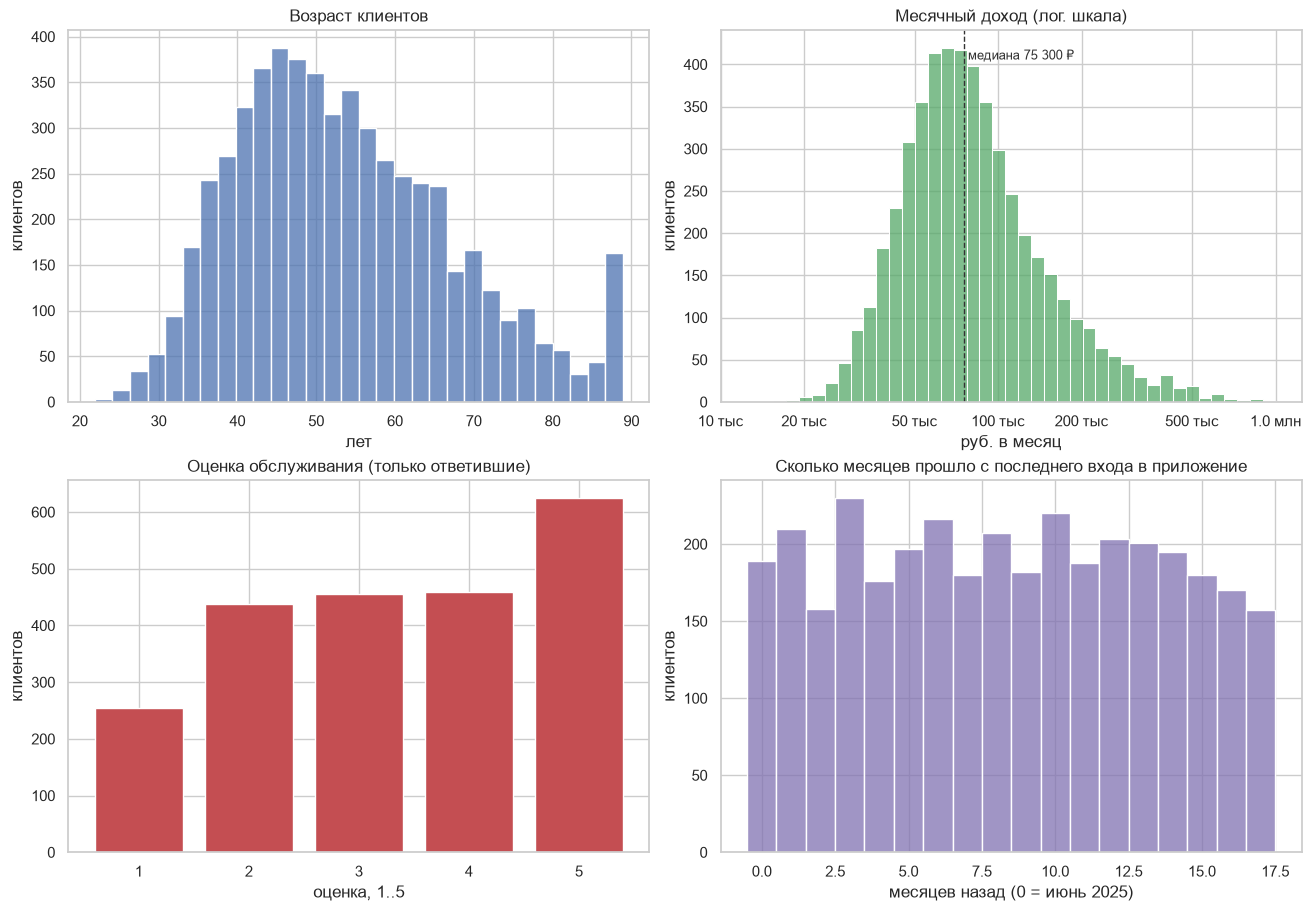

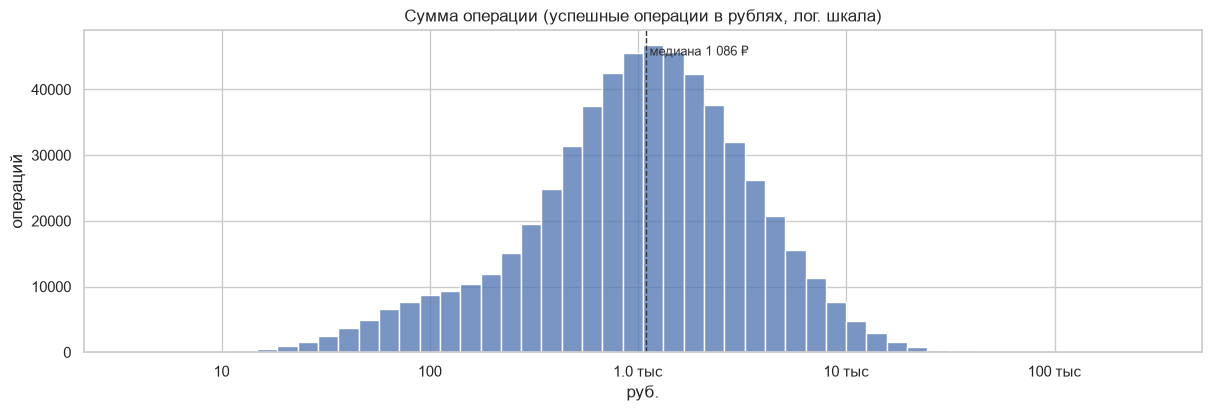

меры центра и разброса (медиана и IQR вместо среднего и std):
                              n   медиана        Q1         Q3       min          max
возраст, лет           5,619.00     51.76     43.27      62.64     21.89        88.93
доход, руб.            5,041.00 75,300.00 54,300.00 111,800.00 13,900.00 1,002,500.00
оценка, 1..5           2,231.00      3.00      2.00       5.00      1.00         5.00
месяцев с входа        3,459.00      8.00      4.00      13.00      0.00        17.00
сумма операции, руб. 582,364.00  1,086.46    488.22   2,280.37      3.85   290,006.83


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")

sns.histplot(clients_clean["age"], bins=30, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Возраст клиентов")
axes[0, 0].set_xlabel("лет")
axes[0, 0].set_ylabel("клиентов")

income = clients_clean["monthly_income"].dropna()
sns.histplot(income, bins=40, log_scale=True, ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Месячный доход (лог. шкала)")
axes[0, 1].set_xlabel("руб. в месяц")
axes[0, 1].set_ylabel("клиентов")
axes[0, 1].axvline(income.median(), color="#333333", ls="--", lw=1)
axes[0, 1].text(income.median(), axes[0, 1].get_ylim()[1] * 0.92,
                f" медиана {income.median():,.0f} ₽".replace(",", " "),
                fontsize=9, color="#333333")
axes[0, 1].set_xticks([10_000, 20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000])
set_money_axis(axes[0, 1])

sat = clients_clean["satisfaction_score"].value_counts().sort_index()
axes[1, 0].bar(sat.index.astype(int), sat.values, color="#C44E52")
axes[1, 0].set_title("Оценка обслуживания (только ответившие)")
axes[1, 0].set_xlabel("оценка, 1..5")
axes[1, 0].set_ylabel("клиентов")

sns.histplot(clients_clean["months_since_login"].dropna(), bins=18, discrete=True, ax=axes[1, 1], color="#8172B2")
axes[1, 1].set_title("Сколько месяцев прошло с последнего входа в приложение")
axes[1, 1].set_xlabel("месяцев назад (0 = июнь 2025)")
axes[1, 1].set_ylabel("клиентов")

plt.show()

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
sns.histplot(txn_clean["amount"], bins=50, log_scale=True, ax=ax, color="#4C72B0")
ax.set_title("Сумма операции (успешные операции в рублях, лог. шкала)")
ax.set_xlabel("руб.")
ax.set_ylabel("операций")
ax.axvline(txn_clean["amount"].median(), color="#333333", ls="--", lw=1)
ax.text(txn_clean["amount"].median(), ax.get_ylim()[1] * 0.92,
        f" медиана {txn_clean['amount'].median():,.0f} ₽".replace(",", " "),
        fontsize=9, color="#333333")
set_money_axis(ax)
plt.show()

def row(s):
    s = s.dropna()
    return {"n": len(s), "медиана": s.median(), "Q1": s.quantile(.25),
            "Q3": s.quantile(.75), "min": s.min(), "max": s.max()}

stats = pd.DataFrame({
    "возраст, лет": row(clients_clean["age"]),
    "доход, руб.": row(clients_clean["monthly_income"]),
    "оценка, 1..5": row(clients_clean["satisfaction_score"].astype(float)),
    "месяцев с входа": row(clients_clean["months_since_login"].astype(float)),
    "сумма операции, руб.": row(txn_clean["amount"]),
}).T

print("меры центра и разброса (медиана и IQR вместо среднего и std):")
print(stats.round(2).to_string())

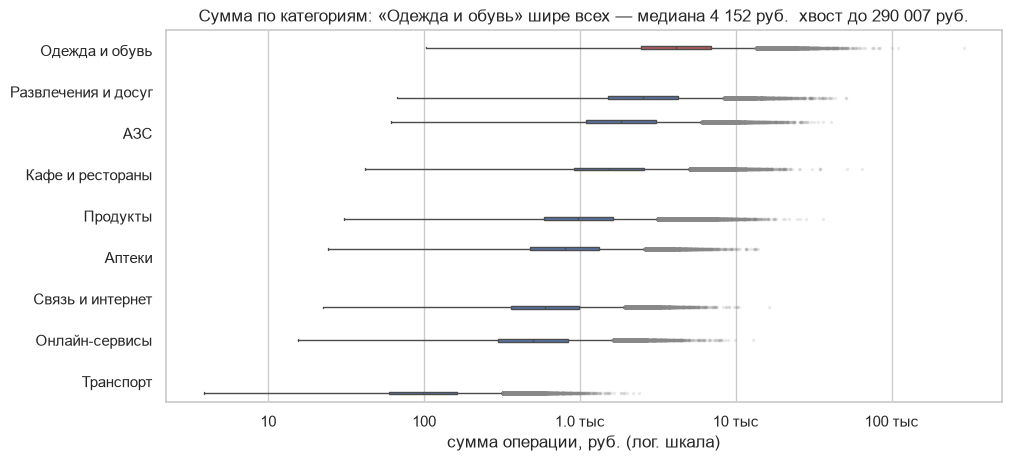

In [24]:

cat_med = txn_clean.groupby("category")["amount"].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
sns.boxplot(
    data=txn_clean, y="category", x="amount", order=cat_med.index[::-1],
    hue="category", legend=False,
    palette={c: ("#C44E52" if c == "Одежда и обувь" else "#4C72B0") for c in cat_med.index},
    flierprops=dict(marker=".", markersize=3, alpha=0.12, mfc="#888888", mec="#888888"),
    width=0.62, linewidth=1)
ax.set_xscale("log")
set_money_axis(ax)
ax.set_xlabel("сумма операции, руб. (лог. шкала)")
ax.set_ylabel("")

med_cl = cat_med["Одежда и обувь"]
max_cl = txn_clean.loc[txn_clean.category == "Одежда и обувь", "amount"].max()
ax.set_title(f"Сумма по категориям: «Одежда и обувь» шире всех — "
             f"медиана {med_cl:,.0f} руб., хвост до {max_cl:,.0f} руб.".replace(",", " "))
plt.show()

In [25]:
snap = pd.Timestamp("2025-06-30")
age_full = ((snap - clients_clean["birth_date"]).dt.days / 365.25).astype(int)
tail = age_full[age_full >= 80].value_counts().sort_index()

print("клиентов по полному возрасту, 80+:")
print(tail.to_string())
print()
print(f"88 лет: {int((age_full == 88).sum())}, 89 лет и старше: {int((age_full >= 89).sum())}")
print(f"самая ранняя дата рождения: {clients_clean.birth_date.min():%d.%m.%Y}")
print(f"максимальный возраст: {clients_clean.age.max():.1f} лет")

клиентов по полному возрасту, 80+:
birth_date
80     31
81     20
82     18
83     14
84     16
85     23
86     14
87     18
88    141

88 лет: 141, 89 лет и старше: 0
самая ранняя дата рождения: 27.07.1936
максимальный возраст: 88.9 лет


### 5.2. Частотные характеристики категориальных признаков

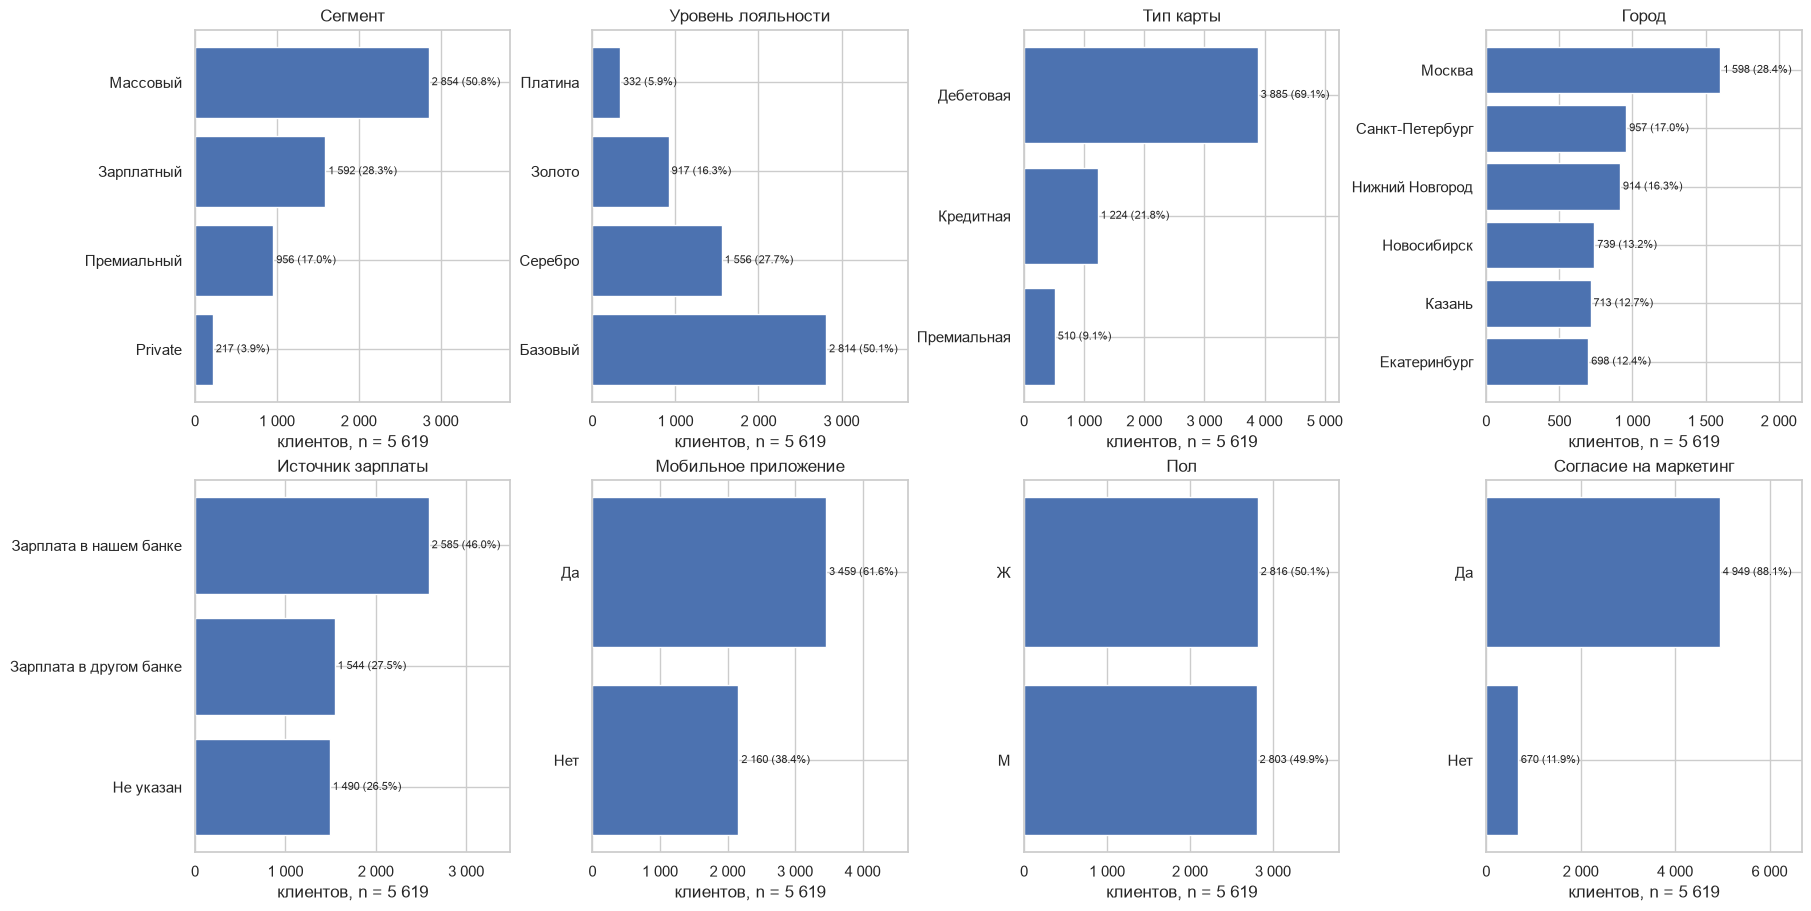

КЛИЕНТЫ, n = 5619
            поле                значение    n  доля, %
          gender                       Ж 2816    50.10
          gender                       М 2803    49.90
            city                  Москва 1598    28.40
            city         Санкт-Петербург  957    17.00
            city         Нижний Новгород  914    16.30
            city             Новосибирск  739    13.20
            city                  Казань  713    12.70
            city            Екатеринбург  698    12.40
         segment                Массовый 2854    50.80
         segment              Зарплатный 1592    28.30
         segment             Премиальный  956    17.00
         segment                 Private  217     3.90
    loyalty_tier                 Базовый 2814    50.10
    loyalty_tier                 Серебро 1556    27.70
    loyalty_tier                  Золото  917    16.30
    loyalty_tier                 Платина  332     5.90
       card_type               Дебетовая 3885  

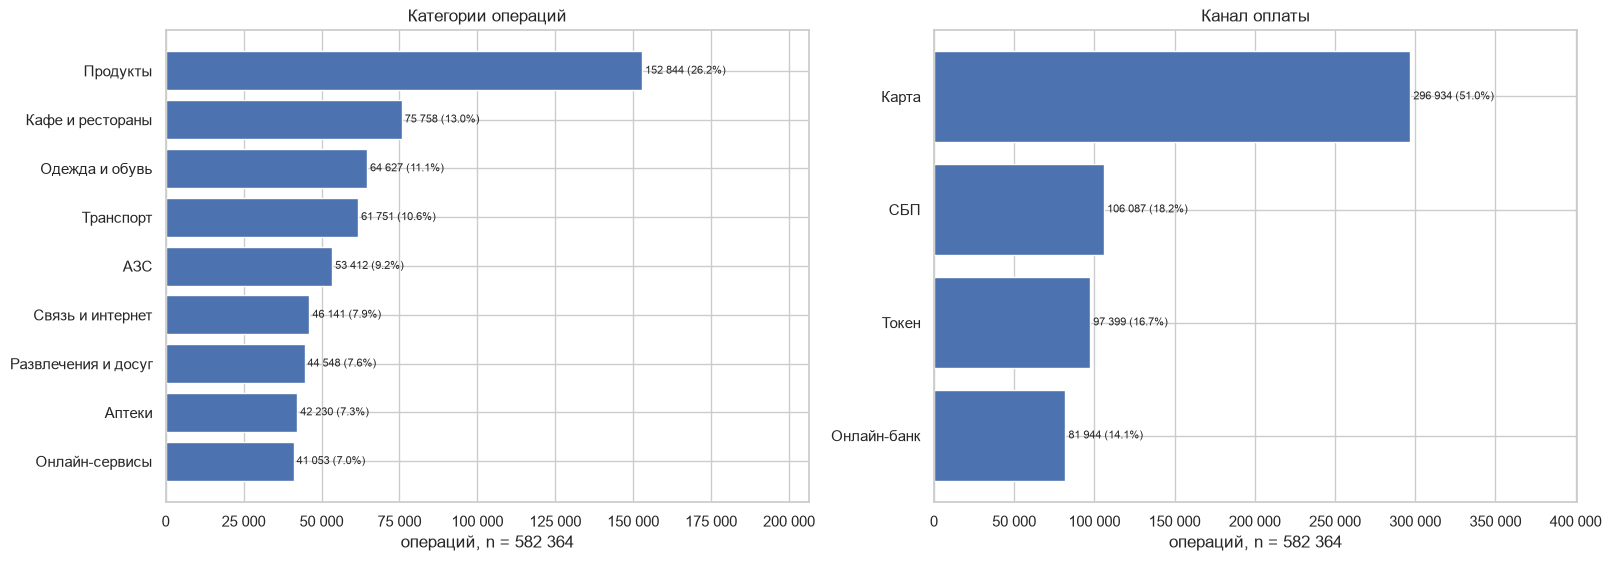


ОПЕРАЦИИ, n = 582364
    поле            значение      n  доля, %
category            Продукты 152844    26.20
category    Кафе и рестораны  75758    13.00
category      Одежда и обувь  64627    11.10
category           Транспорт  61751    10.60
category                 АЗС  53412     9.20
category    Связь и интернет  46141     7.90
category Развлечения и досуг  44548     7.60
category              Аптеки  42230     7.30
category      Онлайн-сервисы  41053     7.00
 channel               Карта 296934    51.00
 channel                 СБП 106087    18.20
 channel               Токен  97399    16.70
 channel         Онлайн-банк  81944    14.10
currency                 RUB 582364   100.00
  status             успешно 582364   100.00


In [26]:

def count_fmt(x, pos=None):
    return f"{x:,.0f}".replace(",", " ")


def cat_bar(ax, s, title, xlabel, sort=True):
    """Горизонтальные столбики: значение, количество и доля от знаменателя."""
    s = s.sort_values() if sort else s
    total = int(s.sum())
    ax.barh(s.index.astype(str), s.values, color="#4C72B0")
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:,} ({v / total * 100:.1f}%)".replace(",", " "),
                va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, max(s.max() * 1.35, 1))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(count_fmt))


def freq_table(data, columns):
    parts = []
    for col in columns:
        vc = data[col].value_counts(dropna=False)
        vc = vc[vc > 0]
        parts.append(pd.DataFrame({
            "поле": col,
            "значение": vc.index.astype(str),
            "n": vc.values,
            "доля, %": (vc.values / len(data) * 100).round(1),
        }))
    return pd.concat(parts, ignore_index=True)


n_clients = len(clients_clean)
xlabel_cl = "клиентов, n = " + f"{n_clients:,}".replace(",", " ")

fig, axes = plt.subplots(2, 4, figsize=(18, 9), layout="constrained")

cat_bar(axes[0, 0], clients_clean.segment.value_counts(), "Сегмент", xlabel_cl)
cat_bar(axes[0, 1], clients_clean.loyalty_tier.value_counts().reindex(LOYALTY_ORDER.categories).fillna(0).astype(int),
        "Уровень лояльности", xlabel_cl, sort=False)
cat_bar(axes[0, 2], clients_clean.card_type.value_counts(), "Тип карты", xlabel_cl)
cat_bar(axes[0, 3], clients_clean.city.value_counts(), "Город", xlabel_cl)
cat_bar(axes[1, 0], clients_clean.income_source.value_counts(), "Источник зарплаты", xlabel_cl)
cat_bar(axes[1, 1], clients_clean.has_mobile_app.value_counts(), "Мобильное приложение", xlabel_cl)
cat_bar(axes[1, 2], clients_clean.gender.value_counts(), "Пол", xlabel_cl)
cat_bar(axes[1, 3], clients_clean.marketing_opt_in.value_counts(), "Согласие на маркетинг", xlabel_cl)

plt.show()

client_cats = ["gender", "city", "segment", "loyalty_tier", "card_type",
               "income_source", "has_mobile_app", "marketing_opt_in"]
print(f"КЛИЕНТЫ, n = {n_clients}")
print(freq_table(clients_clean, client_cats).to_string(index=False))

n_txn = len(txn_clean)
xlabel_tx = "операций, n = " + f"{n_txn:,}".replace(",", " ")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), layout="constrained")
cat_bar(axes[0], txn_clean.category.value_counts(), "Категории операций", xlabel_tx)
cat_bar(axes[1], txn_clean.channel.value_counts(), "Канал оплаты", xlabel_tx)
plt.show()

txn_cats = ["category", "channel", "currency", "status"]
print(f"\nОПЕРАЦИИ, n = {n_txn}")
print(freq_table(txn_clean, txn_cats).to_string(index=False))

### 5.3. Динамика по месяцам

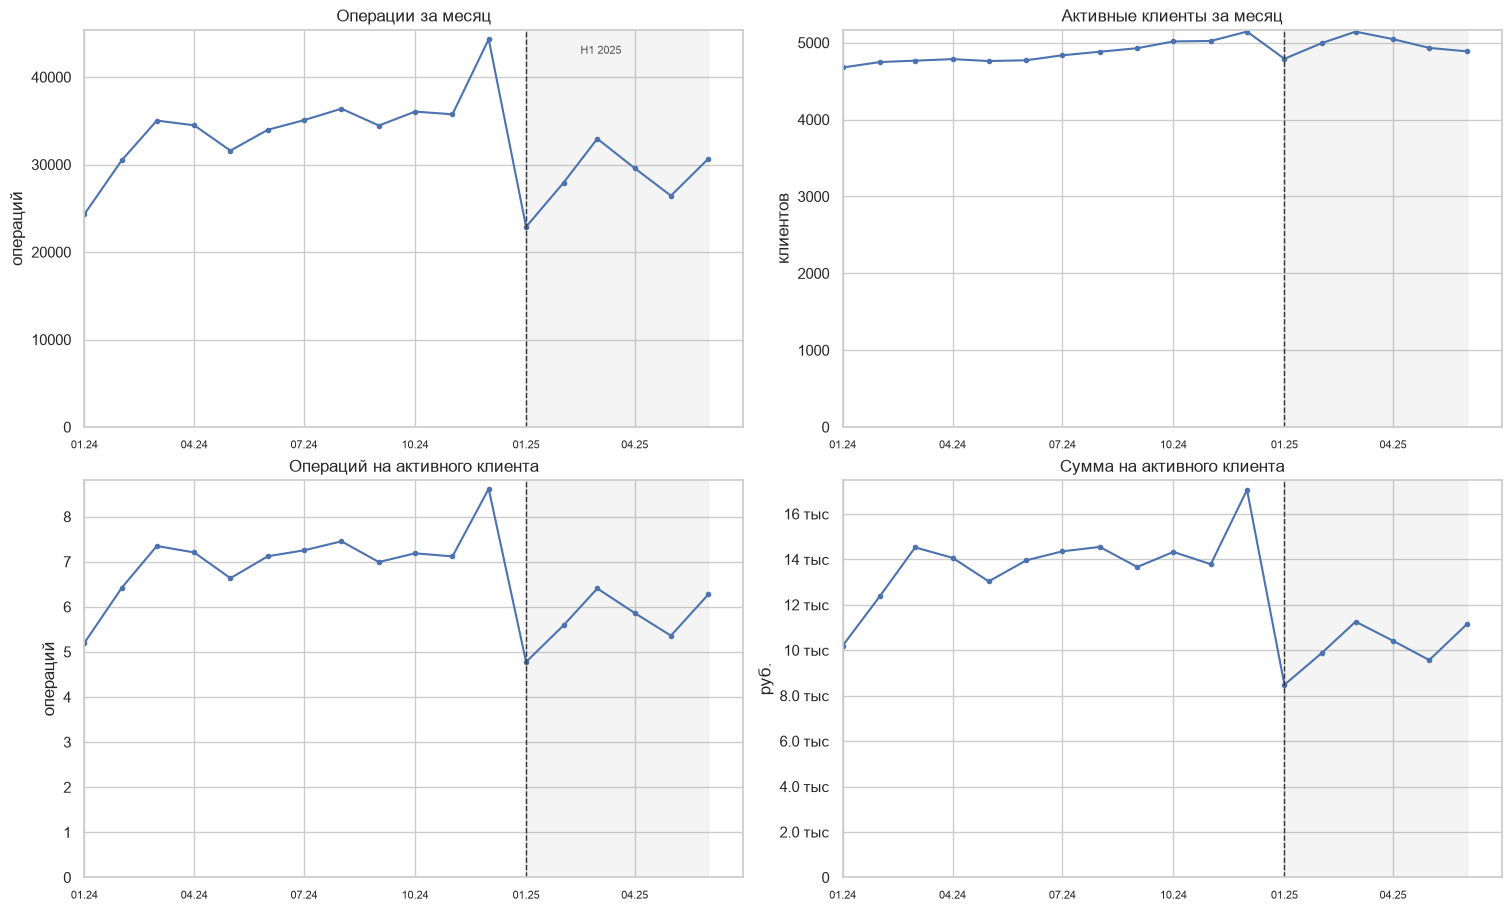

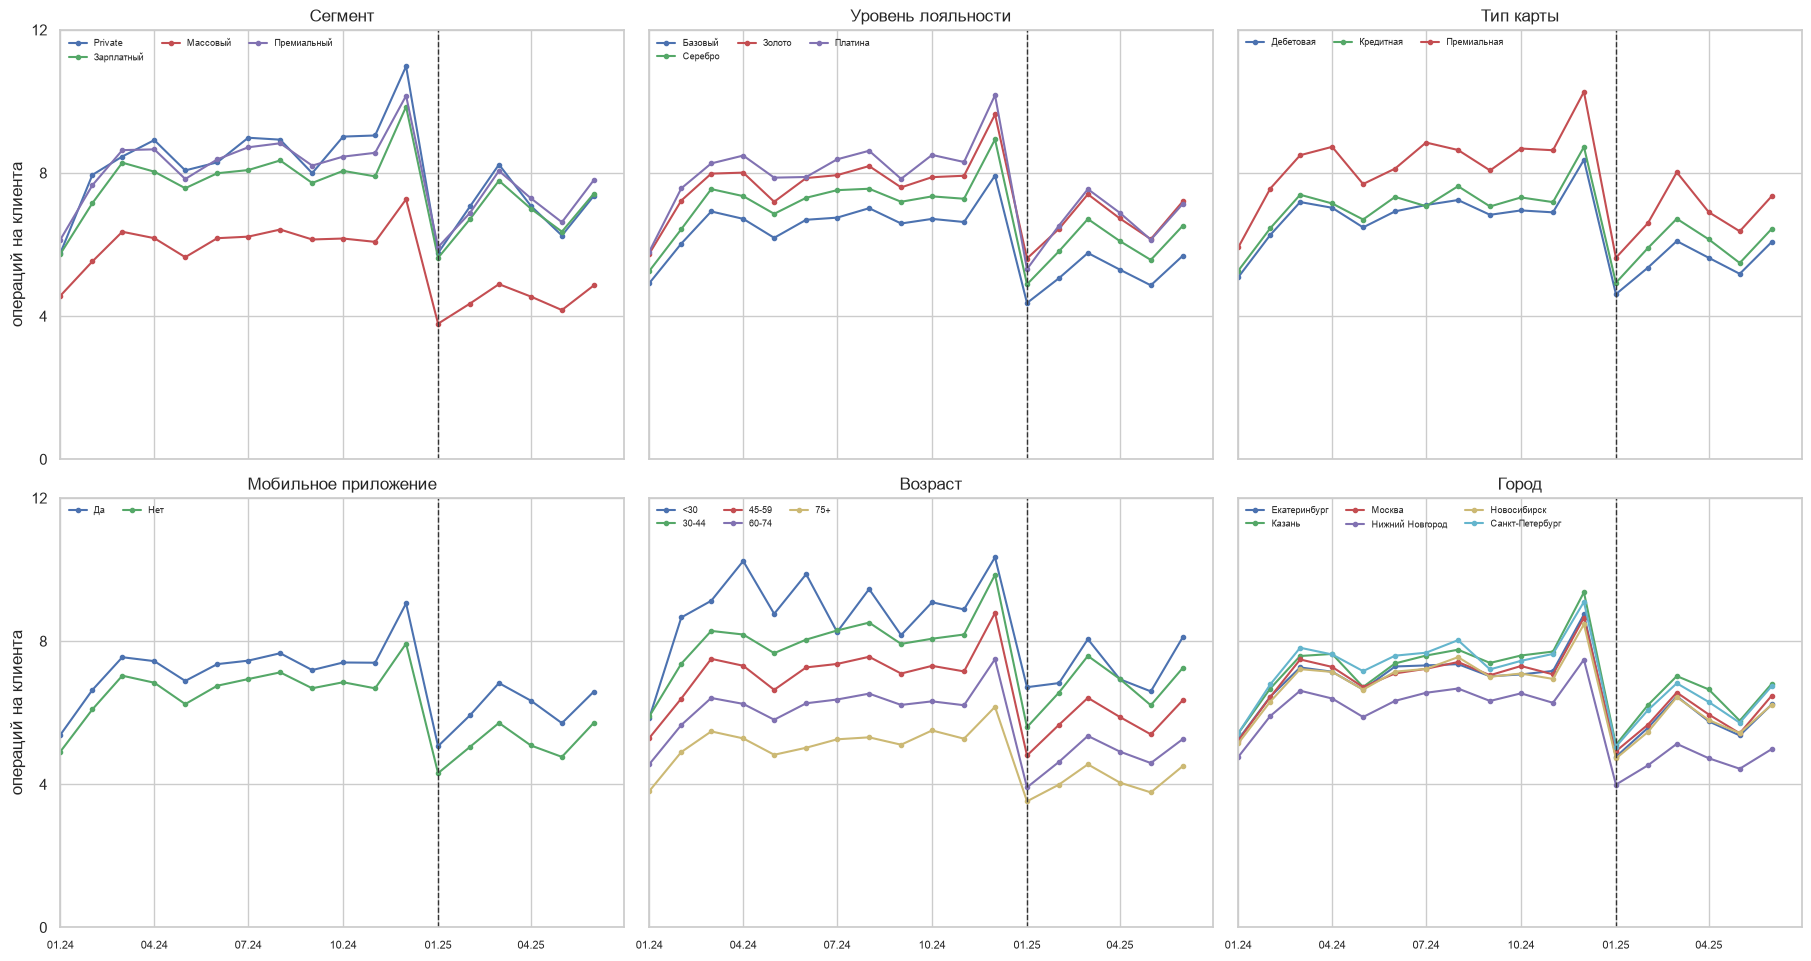

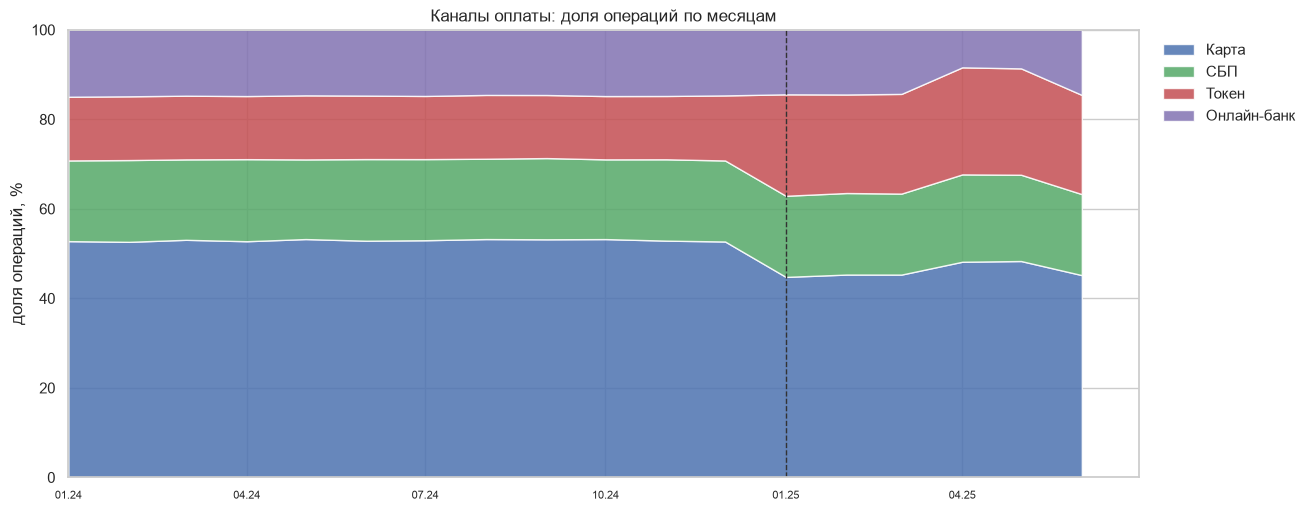

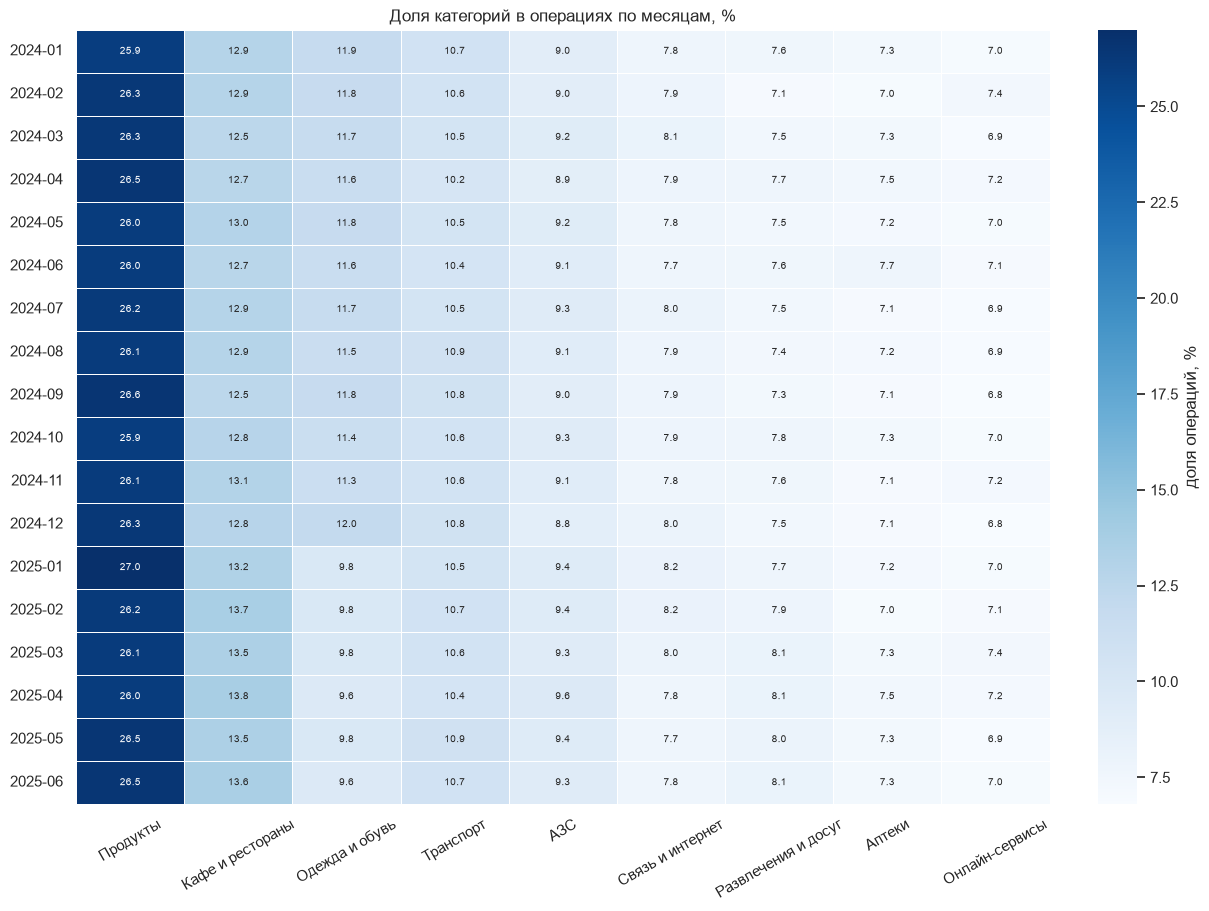

In [27]:
COLORS = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974", "#64B5CD"]


def month_axis(ax):
    ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2025-06-30"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
    ax.tick_params(axis="x", labelsize=8)


def monthly_total(data):
    g = data.groupby(data.txn_datetime.dt.to_period("M")).agg(
        ops=("txn_id", "size"),
        clients=("client_id", "nunique"),
        amount=("amount", "sum"),
    )
    g["ops_per_client"] = g.ops / g.clients
    g["amount_per_client"] = g.amount / g.clients
    return g


def monthly_by(data, by):
    g = (data.assign(month=data.txn_datetime.dt.to_period("M"))
             .groupby(["month", by], observed=True)
             .agg(ops=("txn_id", "size"), clients=("client_id", "nunique"))
             .reset_index())
    g["value"] = g.ops / g.clients
    return g


def plot_attr(ax, by, title):
    g = monthly_by(txn_dim, by)
    for i, (name, part) in enumerate(g.groupby(by, observed=True)):
        ax.plot(part["month"].dt.to_timestamp(), part["value"], marker="o", ms=3,
                lw=1.5, label=str(name), color=COLORS[i % len(COLORS)])
    ax.axvline(pd.Timestamp("2025-01-01"), color="#333333", ls="--", lw=1)
    ax.set_title(title)
    ax.legend(fontsize=6.5, ncol=3, frameon=False, loc="upper left")
    month_axis(ax)


clients_clean["age_group"] = pd.cut(
    clients_clean["age"], [0, 30, 45, 60, 75, 100],
    labels=["<30", "30-44", "45-59", "60-74", "75+"], right=False,
)
txn_dim = txn_clean.merge(
    clients_clean[["client_id", "segment", "loyalty_tier", "card_type",
                   "has_mobile_app", "age_group", "city"]],
    on="client_id", how="left",
)

m = monthly_total(txn_clean)
x = m.index.to_timestamp()

fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
panels = [
    ("ops", "Операции за месяц", "операций"),
    ("clients", "Активные клиенты за месяц", "клиентов"),
    ("ops_per_client", "Операций на активного клиента", "операций"),
    ("amount_per_client", "Сумма на активного клиента", "руб."),
]
for ax, (col, title, ylabel) in zip(axes.flat, panels):
    ax.plot(x, m[col], marker="o", ms=3, color="#4C72B0")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.axvspan(pd.Timestamp("2025-01-01"), x[-1], color="#999999", alpha=0.10)
    ax.axvline(pd.Timestamp("2025-01-01"), color="#333333", ls="--", lw=1)
    ax.set_ylim(0, None)
    month_axis(ax)
set_money_axis(axes[1, 1], "y")
axes[0, 0].text(pd.Timestamp("2025-02-15"), axes[0, 0].get_ylim()[1] * 0.96,
                "H1 2025", fontsize=8, color="#555555", va="top")
plt.show()

attributes = [
    ("segment", "Сегмент"),
    ("loyalty_tier", "Уровень лояльности"),
    ("card_type", "Тип карты"),
    ("has_mobile_app", "Мобильное приложение"),
    ("age_group", "Возраст"),
    ("city", "Город"),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5), layout="constrained", sharey=True)
for ax, (by, title) in zip(axes.flat, attributes):
    plot_attr(ax, by, title)
for ax in axes[:, 0]:
    ax.set_ylabel("операций на клиента")
axes[0, 0].set_ylim(0, 12)
axes[0, 0].set_yticks([0, 4, 8, 12])
for ax in axes[0, :]:
    ax.tick_params(labelbottom=False)
plt.show()

ch = (txn_clean.assign(month=txn_clean.txn_datetime.dt.to_period("M"))
      .pivot_table(index="month", columns="channel", values="txn_id",
                   aggfunc="size", observed=True, fill_value=0))
ch = ch[["Карта", "СБП", "Токен", "Онлайн-банк"]]
ch_share = ch.div(ch.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
ax.stackplot(ch_share.index.to_timestamp(), [ch_share[c] for c in ch_share.columns],
             labels=ch_share.columns, colors=COLORS[:4], alpha=0.85)
ax.set_ylim(0, 100)
ax.set_ylabel("доля операций, %")
ax.set_title("Каналы оплаты: доля операций по месяцам")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.axvline(pd.Timestamp("2025-01-01"), color="#333333", ls="--", lw=1)
month_axis(ax)
plt.show()

cat = (txn_clean.assign(month=txn_clean.txn_datetime.dt.to_period("M"))
       .pivot_table(index="month", columns="category", values="txn_id",
                    aggfunc="size", observed=True, fill_value=0))
cat_share = (cat.div(cat.sum(axis=1), axis=0) * 100).round(1)
cat_share = cat_share[cat_share.mean().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 9), layout="constrained")
sns.heatmap(cat_share, annot=True, fmt=".1f", cmap="Blues",
            annot_kws={"fontsize": 7}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "доля операций, %"}, ax=ax)
ax.set_title("Доля категорий в операциях по месяцам, %")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=30)
plt.show()

### 5.4. Разрезы и связи между признаками

    сегмент приложение  клиентов  с картой 2024  покупали одежду  карта, %  одежда, %
   Массовый         Да      1763           1503             1388    -38.10     -34.90
   Массовый        Нет      1091            980              896    -38.60     -54.30
 Зарплатный         Да       966            805              770    -20.90     -17.60
 Зарплатный        Нет       626            524              495     -5.20     -18.50
Премиальный         Да       586            481              476    -19.00     -28.60
Премиальный        Нет       370            302              297     -6.10     -37.20
    Private         Да       144            122              120    -23.90     -22.40
    Private        Нет        73             62               62    -14.60     -32.60


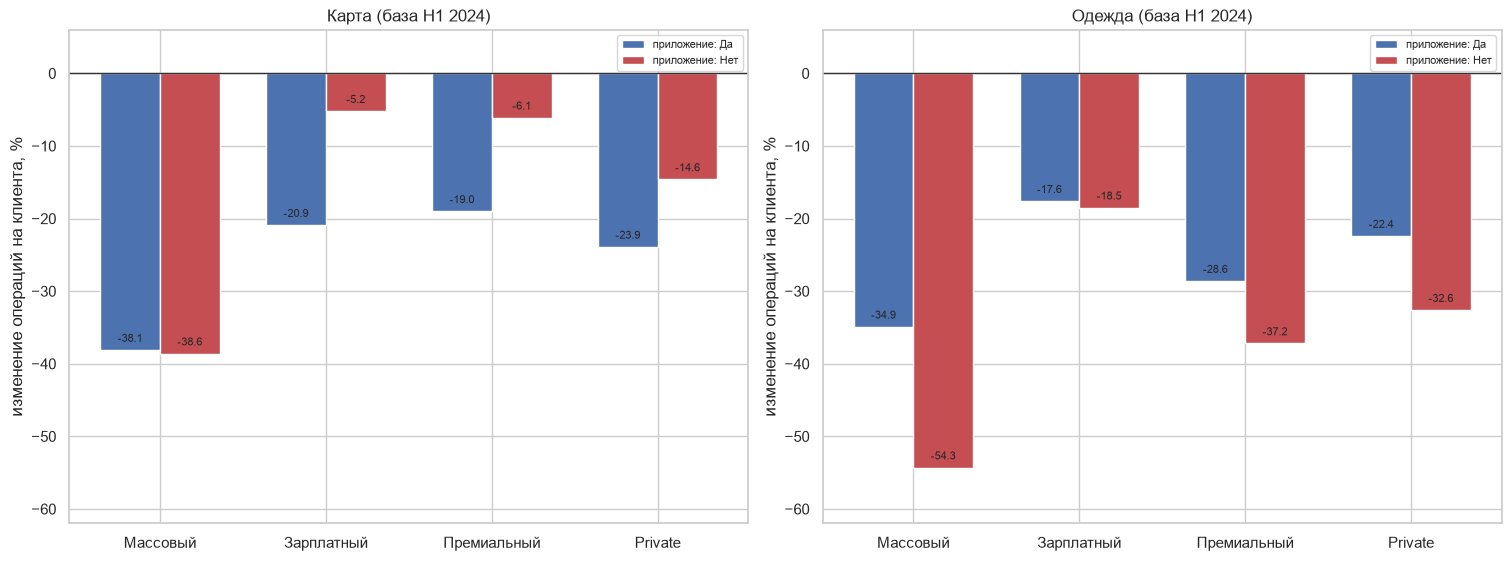

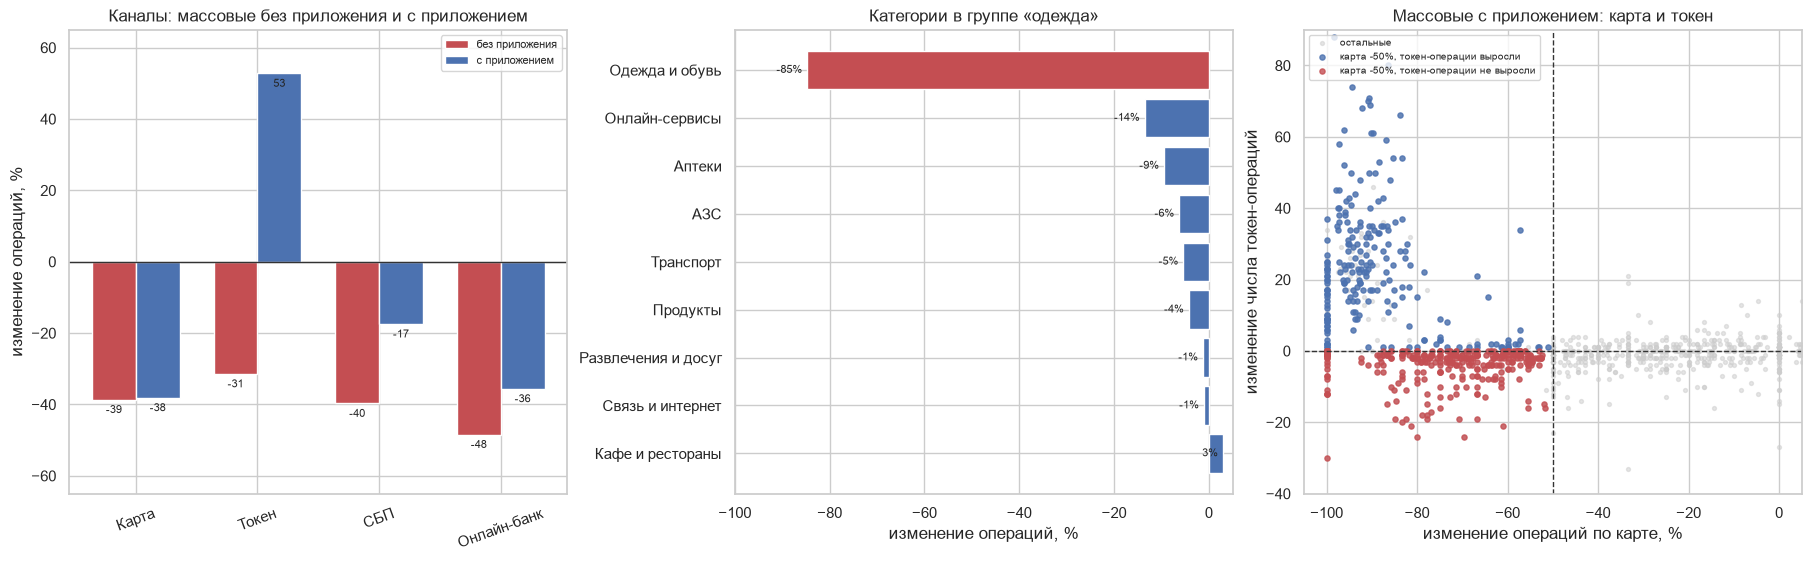

In [28]:
h1 = txn_clean[txn_clean.txn_datetime.dt.month <= 6].copy()
h1["half"] = np.where(h1.txn_datetime.dt.year == 2024, "y24", "y25")


def client_ops(data):
    return (data.groupby(["client_id", "half"]).size().unstack(fill_value=0)
                .reindex(columns=["y24", "y25"], fill_value=0))


card_ops = client_ops(h1[h1.channel == "Карта"]).add_prefix("card_")
tok_ops = client_ops(h1[h1.channel == "Токен"]).add_prefix("tok_")
all_ops = client_ops(h1)
cl_ops = client_ops(h1[h1.category == "Одежда и обувь"]).add_prefix("cl_")

activity = clients_clean.set_index("client_id").join(card_ops).join(tok_ops).join(all_ops).join(cl_ops)
num = ["card_y24", "card_y25", "tok_y24", "tok_y25", "y24", "y25", "cl_y24", "cl_y25"]
activity[num] = activity[num].fillna(0).astype(int)
activity["card_ratio"] = np.where(activity.card_y24 > 0, activity.card_y25 / activity.card_y24, np.nan)
activity["cl_ratio"] = np.where(activity.cl_y24 > 0, activity.cl_y25 / activity.cl_y24, np.nan)
activity["total_ratio"] = np.where(activity.y24 > 0, activity.y25 / activity.y24, np.nan)
activity["tok_share24"] = np.where(activity.y24 > 0, activity.tok_y24 / activity.y24, np.nan)
activity["tok_share25"] = np.where(activity.y25 > 0, activity.tok_y25 / activity.y25, np.nan)

segments = ["Массовый", "Зарплатный", "Премиальный", "Private"]
apps = ["Да", "Нет"]

rows = []
for seg in segments:
    for app in apps:
        g = activity[(activity.segment == seg) & (activity.has_mobile_app == app)]
        bc = g[g.card_y24 > 0]
        bcl = g[g.cl_y24 > 0]
        rows.append({
            "сегмент": seg,
            "приложение": app,
            "клиентов": len(g),
            "с картой 2024": len(bc),
            "покупали одежду": len(bcl),
            "карта, %": (bc.card_y25.mean() / bc.card_y24.mean() - 1) * 100 if len(bc) else np.nan,
            "одежда, %": (bcl.cl_y25.mean() / bcl.cl_y24.mean() - 1) * 100 if len(bcl) else np.nan,
        })

app_tbl = pd.DataFrame(rows).round(1)
print(app_tbl.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
x = np.arange(len(segments))
width = 0.36

for ax, col, title in [(axes[0], "карта, %", "Карта (база H1 2024)"),
                       (axes[1], "одежда, %", "Одежда (база H1 2024)")]:
    for i, app in enumerate(apps):
        vals = app_tbl[app_tbl["приложение"] == app].set_index("сегмент").reindex(segments)[col]
        bars = ax.bar(x + (i - 0.5) * width, vals, width,
                      label=f"приложение: {app}", color=["#4C72B0", "#C44E52"][i])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(segments)
    ax.axhline(0, color="#333333", lw=1)
    ax.set_ylim(-62, 6)
    ax.set_ylabel("изменение операций на клиента, %")
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.show()

g1 = activity[(activity.segment == "Массовый") & (activity.has_mobile_app == "Нет") & (activity.card_y24 > 0)]
ma = activity[(activity.segment == "Массовый") & (activity.has_mobile_app == "Да") & (activity.card_y24 > 0)]
g2 = ma[(ma.cl_y24 > 0) & (ma.cl_ratio < 0.5) & (ma.total_ratio >= 0.5)]
g3 = ma[(ma.card_ratio < 0.5) & (ma.tok_y25 > ma.tok_y24) & ~ma.index.isin(g2.index)]
g4 = ma[(ma.card_ratio < 0.5) & (ma.tok_y25 <= ma.tok_y24) & ~ma.index.isin(g2.index)]


def channel_change(ids):
    d = h1[h1.client_id.isin(ids)]
    p = d.pivot_table(index="channel", columns="half", values="txn_id",
                      aggfunc="size", observed=True, fill_value=0)
    p = p.reindex(["Карта", "Токен", "СБП", "Онлайн-банк"]).fillna(0)
    return (p["y25"] / p["y24"] - 1) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")

ax = axes[0]
ch_g1 = channel_change(g1.index)
ch_app = channel_change(ma.index)
x = np.arange(len(ch_g1))
width = 0.36
ax.bar(x - width / 2, ch_g1.values, width, label="без приложения", color="#C44E52")
ax.bar(x + width / 2, ch_app.values, width, label="с приложением", color="#4C72B0")
for i, (a, b) in enumerate(zip(ch_g1.values, ch_app.values)):
    ax.text(i - width / 2, a - 1.5, f"{a:.0f}", ha="center", va="top", fontsize=8)
    ax.text(i + width / 2, b - 1.5, f"{b:.0f}", ha="center", va="top", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ch_g1.index, rotation=20)
ax.axhline(0, color="#333333", lw=1)
ax.set_ylim(-65, 65)
ax.set_ylabel("изменение операций, %")
ax.set_title("Каналы: массовые без приложения и с приложением")
ax.legend(fontsize=8)

ax = axes[1]
d = h1[h1.client_id.isin(g2.index)]
cat = d.pivot_table(index="category", columns="half", values="txn_id",
                    aggfunc="size", observed=True, fill_value=0)
cat["change"] = np.where(cat["y24"] > 0, (cat["y25"] / cat["y24"] - 1) * 100, np.nan)
cat = cat.dropna(subset=["change"]).sort_values("change", ascending=False)
colors = ["#C44E52" if c == "Одежда и обувь" else "#4C72B0" for c in cat.index]
ax.barh(cat.index, cat["change"], color=colors)
for y, v in enumerate(cat["change"]):
    ax.text(v - 1, y, f"{v:.0f}%", ha="right", va="center", fontsize=8)
ax.set_xlim(-100, 5)
ax.set_xlabel("изменение операций, %")
ax.set_title("Категории в группе «одежда»")

ax = axes[2]
ax.scatter(ma.card_ratio * 100 - 100, ma.tok_y25 - ma.tok_y24,
           s=8, color="#CCCCCC", alpha=0.5, label="остальные")
ax.scatter(g3.card_ratio * 100 - 100, g3.tok_y25 - g3.tok_y24,
           s=14, color="#4C72B0", alpha=0.8, label="карта -50%, токен-операции выросли")
ax.scatter(g4.card_ratio * 100 - 100, g4.tok_y25 - g4.tok_y24,
           s=14, color="#C44E52", alpha=0.8, label="карта -50%, токен-операции не выросли")
ax.axvline(-50, color="#333333", ls="--", lw=1)
ax.axhline(0, color="#333333", ls="--", lw=1)
ax.set_xlim(-105, 5)
ax.set_ylim(-40, 90)
ax.set_xlabel("изменение операций по карте, %")
ax.set_ylabel("изменение числа токен-операций")
ax.set_title("Массовые с приложением: карта и токен")
ax.legend(fontsize=7, loc="upper left")

plt.show()

## 6. Метрика активности

**Что считаем.** Успешную операцию по карте: канал «Карта», статус «успешно».
Отклонённые операции и возвраты не считаем.

**Метрика.** Среднее число операций по карте на одного клиента в месяц:

операции по карте за месяц / 5 619 клиентов

В справочнике у всех клиентов есть карта, поэтому все клиенты — держатели карт.

**Окна.** База — первая половина 2024, оценка — первая половина 2025. Не используем вторую половину 2024 так как нет данных
    по второй половине 2025.

**Разложение.** операций на клиента = охват × интенсивность:

- охват — доля клиентов, у которых была хотя бы одна операция по карте в месяце;
- интенсивность — операций на одного такого клиента.

**Что метрика не увидит.**

1. Переток в токен: клиент, который платит через токен, выглядит как падение карты.
2. Размер транзакции, метрика видит только количество операций
3. Уход клиентов из банка, снимок данных только до 30.06.2025
4. Категории трат: не видно, активность какой категории падает.
5. Новых клиентов: они входят в знаменатель и могут тянуть среднее вниз.

карта, H1 2024 -> H1 2025
         per_client  reach  intensity
half                                 
H1 2024        2.98  73.54       4.04
H1 2025        2.33  68.31       3.41

операций на клиента: 2.98 -> 2.33 (-21.6%)
охват: 73.5% -> 68.3% (-5.2 п.п.)
интенсивность: 4.04 -> 3.41 (-15.7%)

2024 в среднем: 3.24 операции на клиента в месяц


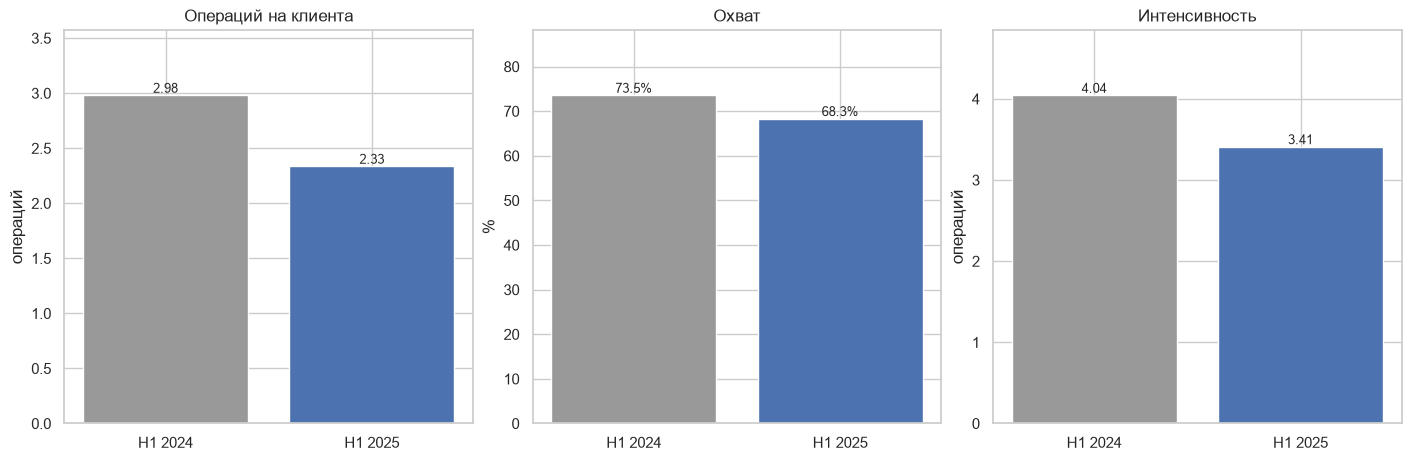

In [29]:
n_clients = len(clients_clean)

card = txn_clean[(txn_clean.channel == "Карта") &
                 (txn_clean.txn_datetime.dt.month <= 6)].copy()
card["month"] = card.txn_datetime.dt.to_period("M")

monthly = card.groupby("month").agg(
    ops=("txn_id", "size"),
    active=("client_id", "nunique"),
)
monthly["per_client"] = monthly.ops / n_clients
monthly["reach"] = monthly.active / n_clients * 100
monthly["intensity"] = monthly.ops / monthly.active
monthly["half"] = np.where(monthly.index.year == 2024, "H1 2024", "H1 2025")

summary = monthly.groupby("half").agg(
    per_client=("per_client", "mean"),
    reach=("reach", "mean"),
    intensity=("intensity", "mean"),
).reindex(["H1 2024", "H1 2025"])

print("карта, H1 2024 -> H1 2025")
print(summary.round(2).to_string())

a = summary.loc["H1 2024"]
b = summary.loc["H1 2025"]
print(f"\nопераций на клиента: {a.per_client:.2f} -> {b.per_client:.2f} ({(b.per_client / a.per_client - 1) * 100:+.1f}%)")
print(f"охват: {a.reach:.1f}% -> {b.reach:.1f}% ({b.reach - a.reach:+.1f} п.п.)")
print(f"интенсивность: {a.intensity:.2f} -> {b.intensity:.2f} ({(b.intensity / a.intensity - 1) * 100:+.1f}%)")

card_full24 = txn_clean[(txn_clean.channel == "Карта") &
                        (txn_clean.txn_datetime.dt.year == 2024)]
print(f"\n2024 в среднем: {len(card_full24) / n_clients / 12:.2f} операции на клиента в месяц")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
panels = [("per_client", "Операций на клиента", "операций"),
          ("reach", "Охват", "%"),
          ("intensity", "Интенсивность", "операций")]
for ax, (col, title, ylabel) in zip(axes, panels):
    vals = summary[col]
    bars = ax.bar(vals.index, vals.values, color=["#999999", "#4C72B0"])
    for bar, v in zip(bars, vals.values):
        text = f"{v:.1f}%" if col == "reach" else f"{v:.2f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, text, ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals) * 1.2)
plt.show()

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

### Состав групп

Все четыре группы — массовый сегмент: именно там падение карты сильнее всего.

| # | Кто | Что произошло | Клиентов | С согласием |
|---|---|---|---:|---:|
| 1 | Массовые без приложения, пользовались картой | все каналы и категории вниз, карта −38,6% | 980 | 862 |
| 2 | Массовые с приложением | одежда упала на 84,7%, остальное — меньше чем вдвое | 284 | 251 |
| 3 | Массовые с приложением, пользовались картой | ушли с карты в токен, общая активность стабильна | 216 | 193 |
| 4 | Массовые с приложением, пользовались картой | карта и токен упали, покупки сократились на 66% | 314 | 280 |

| Показатель | Значение |
|---|---:|
| Всего клиентов | 1 794 |
| С согласием | 1 586 |

### 1. Массовые без приложения

**Правило отбора:** массовый сегмент, нет мобильного приложения, была хотя бы одна операция по карте в первой половине 2024 года.

**Что произошло:** активность по карте −38,6%, СБП −39,7%, онлайн-банк −48,4%, активность по всем категориям −35…−51%.

**Что предлагать:** Так как у клиентов данной группы наблюдается падение по всем категориям - предлагать стоит кешбек/бонусные баллы за покупки в повседневных категориях: «Продукты», «Аптеки», «Транспорт». Сообщение отправлять через SMS/звонок в связи с отсутствием приложения.

### 2. Массовые с приложением, упала одежда

**Правило отбора:** массовый сегмент, есть приложение, была карта в первой половине 2024 года, покупки одежды упали больше чем вдвое, общая активность упала меньше чем вдвое.

**Что произошло:** одежда −84,7% по всем способам оплаты (карта −86,6%, онлайн −89,3%, СБП −84,1%, токен −74,6%). Остальные категории — от −14% до +3%. Карта всего −32,4%, общая активность −18,2%.

**Что предлагать:** скидки или кэшбэк на одежду

### 3. Массовые с приложением, ушли с карты в токен

**Правило отбора:** массовый сегмент, есть приложение, была карта в первой половине 2024 года, активность по карте упала больше чем вдвое, токен-операции выросли.

**Что произошло:** активность по карте −89,8%, токен +1076%, общая активность −5,3%. В этой группе клиенты в основном перешли с карты на токен.

**Что предлагать:**
1) Короткий опрос: что стало ключевым фактором перехода на токен — причины перехода в данных нет (бонус за заполнение; помнить про низкую отзываемость опросов из 3.3).
2) Бонус за покупку пластиковой картой — точечно 43 клиентам, которые потеряли карту совсем.
3) Бонус за комбинирование способов: карта и токен в одном месяце — так платят 80% группы. Бонус удерживает баланс и не заставляет клиентов переходить на другой способ оплаты

### 4. Массовые с приложением, резко сократили покупки

**Правило:** массовый сегмент, есть приложение, была карта в первой половине 2024 года, активность по карте упала больше чем вдвое, токен-операции не выросли.

**Что произошло:** активность по карте −69,9%, токен −63,6%, общая активность −66,0%, все категории −63…−68%. Клиент в данной группе резко сократил операции по всем каналам и категориям, но не ушёл: 99,4% продолжают покупать, в среднем 12 операций за полгода против ~36.

**Что предлагать:** бонус за 2–3 покупки, кэшбэк на любые категории, персональное предложение. 

### Конфликты

**Конфликт возможен между группой 2 и группами 3/4. Если клиент попадает под несколько групп, относить его надо в группу 2 — с одеждой.**

In [30]:


g1 = activity[
    (activity.segment == "Массовый") &
    (activity.has_mobile_app == "Нет") &
    (activity.card_y24 > 0)
].copy()
g1["group"] = "1. Массовые без приложения"

g2 = activity[
    (activity.segment == "Массовый") &
    (activity.has_mobile_app == "Да") &
    (activity.card_y24 > 0) &
    (activity.cl_y24 > 0) &
    (activity.cl_ratio < 0.5) &
    (activity.total_ratio >= 0.5)
].copy()
g2["group"] = "2. Массовые с приложением, одежда"

g3_all = activity[
    (activity.segment == "Массовый") &
    (activity.has_mobile_app == "Да") &
    (activity.card_y24 > 0) &
    (activity.card_ratio < 0.5) &
    (activity.tok_y25 > activity.tok_y24)
]
g4_all = activity[
    (activity.segment == "Массовый") &
    (activity.has_mobile_app == "Да") &
    (activity.card_y24 > 0) &
    (activity.card_ratio < 0.5) &
    (activity.tok_y25 <= activity.tok_y24)
]

conflict = g2.index.intersection(g3_all.index.union(g4_all.index))
print(f"подходят под группу 2 и 3/4: {len(conflict)} -> относим в группу 2")

g3 = g3_all[~g3_all.index.isin(g2.index)].copy()
g3["group"] = "3. Массовые с приложением, ушли в токен"

g4 = g4_all[~g4_all.index.isin(g2.index)].copy()
g4["group"] = "4. Массовые с приложением, резкое падение"

campaign = pd.concat([g1, g2, g3, g4])
print(f"клиентов в группах: {len(campaign)}, уникальных: {campaign.index.nunique()}")
print(f"дублей client_id: {campaign.index.duplicated().sum()}")
print(f"с согласием: {int((campaign.marketing_opt_in == 'Да').sum())}")


def group_stats(g):
    b_card = g[g.card_y24 > 0]
    b_total = g[g.y24 > 0]
    b_cl = g[g.cl_y24 > 0]
    b_tok = g[g.tok_y24 > 0]
    return pd.Series({
        "клиентов": len(g),
        "с согласием": int((g.marketing_opt_in == "Да").sum()),
        "карта, %": (b_card.card_y25.mean() / b_card.card_y24.mean() - 1) * 100 if len(b_card) else np.nan,
        "общая, %": (b_total.y25.mean() / b_total.y24.mean() - 1) * 100 if len(b_total) else np.nan,
        "одежда, %": (b_cl.cl_y25.mean() / b_cl.cl_y24.mean() - 1) * 100 if len(b_cl) else np.nan,
        "токен, %": (b_tok.tok_y25.mean() / b_tok.tok_y24.mean() - 1) * 100 if len(b_tok) else np.nan,
    })


result = campaign.groupby("group").apply(group_stats, include_groups=False).round(1)
print("\nгруппы:")
print(result.to_string())
print(f"\nвсего клиентов: {len(campaign)}, с согласием: {int((campaign.marketing_opt_in == 'Да').sum())}")

# числа к блоку «Что предлагать» в markdown выше
print(f"карта на клиента в месяц, группа 3: {g3.card_y24.mean() / 6:.2f} -> {g3.card_y25.mean() / 6:.2f}")
print(f"группа 3 в H1 2025: платят картой {(g3.card_y25 > 0).mean() * 100:.0f}%, совмещают карту и токен "
      f"{((g3.card_y25 > 0) & (g3.tok_y25 > 0)).mean() * 100:.0f}%, карту потеряли совсем {int(((g3.card_y24 > 0) & (g3.card_y25 == 0)).sum())}")
g4_act = activity.loc[g4.index, ["y24", "y25"]]
print(f"все операции на клиента за полгода, группа 4: {g4_act.y24.mean():.1f} -> {g4_act.y25.mean():.1f}")
print(f"группа 4 с хотя бы одной операцией в H1 2025: {(g4_act.y25 > 0).mean() * 100:.1f}%")

подходят под группу 2 и 3/4: 76 -> относим в группу 2
клиентов в группах: 1794, уникальных: 1794
дублей client_id: 0
с согласием: 1586

группы:
                                           клиентов  с согласием  карта, %  общая, %  одежда, %  токен, %
group                                                                                                    
1. Массовые без приложения                   980.00       862.00    -38.60    -39.70     -54.00    -36.00
2. Массовые с приложением, одежда            284.00       251.00    -32.40    -18.20     -84.70     24.80
3. Массовые с приложением, ушли в токен      216.00       193.00    -89.80     -5.30       9.70  1,076.40
4. Массовые с приложением, резкое падение    314.00       280.00    -69.90    -66.00     -67.70    -63.60

всего клиентов: 1794, с согласием: 1586
карта на клиента в месяц, группа 3: 4.42 -> 0.45
группа 3 в H1 2025: платят картой 80%, совмещают карту и токен 80%, карту потеряли совсем 43
все операции на клиента за полгода, г

### 7.1. Кого в кампанию не берём и почему

**В кампанию не попадает 4033 клиента из 5619 клиентов:**
1. У 670 клиентов нет согласия на маркетинг, из них 208 попали в группы кампании, но никакие услуги предлагаться им не будут.
2. 2765 клиентов не массового сегмента (зарплатный, премиальный, private) - у них среднее количество операций по карте 4,04, против 3,01 у массового в 2024 году
3. 689 клиентов массового сегмента с приложением и картой, у которых активность по карте упала менее чем на 50%. Под группу 1 они не попадают из-за наличия приложения.
4. 371 клиент массового сегмента без операций по карте в первой половине 2024 года. Нет основы для расчета метрики активности

In [31]:
total = len(activity)
in_groups = len(campaign)
consent_groups = int((campaign.marketing_opt_in == "Да").sum())
not_campaign = total - consent_groups

no_consent = int((activity.marketing_opt_in != "Да").sum())
no_consent_in_groups = int((campaign.marketing_opt_in != "Да").sum())

nonmass = activity[activity.segment != "Массовый"]
mass = activity[activity.segment == "Массовый"]
mass_no_card = mass[mass.card_y24 == 0]
mass_card_notin = mass[(mass.card_y24 > 0) & (mass.has_mobile_app == "Да") &
                       ~mass.index.isin(campaign.index)]

mass_card_users = mass[mass.card_y24 > 0]
nonmass_card_users = nonmass[nonmass.card_y24 > 0]

print(f"всего клиентов: {total}")
print(f"в кампании: {in_groups}, с согласием: {consent_groups}")
print(f"не в кампании: {not_campaign}")

print(f"\nбез согласия: {no_consent}, из них в группах: {no_consent_in_groups}")
print(f"не массовый сегмент: {len(nonmass)}")
print(f"массовые без карты в H1 2024: {len(mass_no_card)}")
print(f"массовые с приложением и картой, но не в группах: {len(mass_card_notin)}")

print(f"\nпроверка: {len(nonmass)} + {len(mass_no_card)} + {len(mass_card_notin)} = "
      f"{len(nonmass) + len(mass_no_card) + len(mass_card_notin)}")
print(f"плюс {no_consent_in_groups} из групп без согласия = "
      f"{len(nonmass) + len(mass_no_card) + len(mass_card_notin) + no_consent_in_groups}")

print("\nсреднее число операций по карте на клиента в месяц:")
print(f"  массовый: 2024 {mass_card_users.card_y24.mean() / 6:.2f}, "
      f"2025 {mass_card_users.card_y25.mean() / 6:.2f}")
print(f"  не массовый: 2024 {nonmass_card_users.card_y24.mean() / 6:.2f}, "
      f"2025 {nonmass_card_users.card_y25.mean() / 6:.2f}")

print("\nмассовые с приложением и картой не в группах:")
print(f"  карта упала меньше 30%: {int((mass_card_notin.card_ratio > 0.7).sum())}")
print(f"  карта упала на 30-50%: {int(((mass_card_notin.card_ratio > 0.5) & (mass_card_notin.card_ratio <= 0.7)).sum())}")
print(f"  всего с падением меньше 50%: {int((mass_card_notin.card_ratio >= 0.5).sum())}")
print(f"\nв группе 1 (массовые без приложения): {len(g1)}")

всего клиентов: 5619
в кампании: 1794, с согласием: 1586
не в кампании: 4033

без согласия: 670, из них в группах: 208
не массовый сегмент: 2765
массовые без карты в H1 2024: 371
массовые с приложением и картой, но не в группах: 689

проверка: 2765 + 371 + 689 = 3825
плюс 208 из групп без согласия = 4033

среднее число операций по карте на клиента в месяц:
  массовый: 2024 3.01, 2025 1.85
  не массовый: 2024 4.04, 2025 3.44

массовые с приложением и картой не в группах:
  карта упала меньше 30%: 537
  карта упала на 30-50%: 112
  всего с падением меньше 50%: 689

в группе 1 (массовые без приложения): 980


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

Все проценты — изменение с первой половины 2024 на первую половину 2025. «Карта» — операции по карте на клиента; «одежда» — операции по одежде; «все операции» — все каналы.

| # | Гипотеза | Что проверялось | Результат |
|---|---|---|---|
| 1 | Город влияет на активность клиентов | Изменение операций по карте в массовом сегменте, H1 2024 → H1 2025 | НН -39,7%, СПб -41,2%, Москва -37,8%, Новосибирск -37,2%, Казань -36,8%, Екатеринбург -34,8%. Худший город — не НН, а Санкт-Петербург. Гипотеза не подтвердилась |
| 2 | Активность клиентов 75+ падает сильнее | Изменение операций по карте по возрастам, массовый сегмент | <30: -53,7% (31 клиент), 30–44: -42,5%, 45–59: -34,9%, 60–74: -39,3%, 75+: -39,3%. 75+ не падают сильнее. Гипотеза не подтвердилась |
| 3 | Уровень лояльности объясняет падение | Изменение операций по карте по уровням лояльности | Базовый -29,9%, Золото -16,2%. 70% базовых — это массовые клиенты. Внутри массового сегмента падение у всех уровней лояльности одинаковое: -37,0…-39,7%. Гипотеза не подтвердилась |
| 4 | Тип карты объясняет падение | Изменение операций по карте по типам карт | Дебетовая -27,5%, Кредитная -21,0%, Премиальная -20,0%. 80% дебетовых — это массовые клиенты. Внутри массового сегмента падение у всех типов карт одинаковое: -38,2…-38,7%. Гипотеза не подтвердилась |
| 5 | Зарплатный и премиальный сегменты падают так же сильно, как массовый | Изменение операций по карте по сегментам, затем по всем операциям | Зарплатный -14,6%, Премиальный -14,0% против массового -38,3%. Падение в ~2,6 раза меньше; на всех операциях у зарплатного и премиального -0,7…-7,0%. Гипотеза не подтвердилась |
| 6 | Одежда упала только по карте | Изменение операций по одежде по каналам в группе 2 | Одежда -84,7%; карта -86,6%, онлайн -89,3%, СБП -84,1%, токен -74,6%. Одежда упала во всех каналах, не только по карте. Гипотеза не подтвердилась |
| 7 | Рост токена — увеличение охвата | Токен-операции и пользователи | Пользователи +4,4%, охват 84,4% → 76,3%, интенсивность 6,6 → 9,1; 75% прироста дали существующие пользователи. Гипотеза не подтвердилась |
| 8 | Падение — это уход клиентов | Активные клиенты за H1 и операции по карте | Активных клиентов 4 859 → 5 609; карта на клиента в месяц -21,6%; месячный охват картой 73,5% → 68,3%. Падение за счёт частоты и охвата карты, а не ухода из банка. Гипотеза не подтвердилась |
| 9 | Массовые без приложения ушли в другой канал | Операции по каналам в группе 1 | Карта -38,6%, СБП -39,7%, онлайн -48,4%, токен -31,4%. Все каналы вниз. Гипотеза не подтвердилась |

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [32]:
clean = txn_dim
clean.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign.reset_index()[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")